# 301_05 — PSBPM-FD con cuatro predictores y tres intervalos contra FAR y RF · Escenario GARCH en los scores · **barrido en $M$**

Copia del `200_05` sobre los artefactos de la 301 y lo que persiste `301_04`: una fila por predictor en el Bloque A, una banda por construcción en el Bloque B (`111_*` contra el FAR), §9 y §10 sobre la ventana de detalle. Cálculo en `fit/comparacion_barrido.py`, figuras en `graphics/viz_comparacion.py`.

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from model_psbp_fd.fit.convergencia_barrido import cargar_artefactos
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB, cargar_representaciones, serie_origenes,
)
from model_psbp_fd.fit.comparacion_barrido import (
    G_FAR, G_PSG, G_PSB, G_PSS, G_PSH, PISO, bloqueB_contra_far,
    preparar_diseno, info_generador, ajustar_far, ajustar_rf, cargar_psbp,
    tablas_modelos, verificar_cadena_modelos,
    construir_bandas, tabla_bloque_B, ventana_bloque_B,
    ganadores_por_ventana, resumen_min_max, promedio_vs_M,
    origenes_extremos, contraste_origenes, nombre_psbp, validar_comportamientos_barrido,
)
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.fit.intervalos_predictiva import INTERVALOS as INTERVALOS_TODOS
from model_psbp_fd.fit.comportamientos import cargar_comportamientos, validar_observado
from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.graphics import (
    plot_ventana_movil, ESTILOS_MODELOS, ESTILOS_MODELOS_PREDICTORES, ESTILOS_BANDAS, plot_validacion_observado,
    plot_ganador_modelo, plot_metricas_vs_M, plot_bandas_contraste,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 301_01 §1.1 (la 201 con otro BASENAME).
VARIANTE     = "chungEscG"
BASENAME     = f"escenario_301_{VARIANTE}"
ESCENARIO_ID = 1      # escenario GARCH en los scores (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)

# Propias de la comparación. Ventanas, nivel y objetivo se LEEN de eval_config.json
# (artefacto copiado de 201_01): no se redeclaran aquí.
PESOS_TAU = None          # cuadratura trapezoidal por defecto
PREFIJO   = 70            # este notebook escribe 70-83 en cada M y 96-99, 105-107, 111 en el barrido
PREDICTORES = PREDICTORES_TODOS   # una fila del PSBPM-FD por predictor puntual (301_04 §3)
INTERVALOS  = INTERVALOS_TODOS    # una banda del PSBPM-FD por construccion (301_04 §3)

# FAR (§3.1): tope del barrido de kn (acota en K, no en L) y criterio de far.cv.
KN_MAX      = 12
CRITERIO_KN = "L2"

# Random Forest (§3.2): hiperparámetros fijos entre escenarios y entre puntos del barrido.
SEED_ML   = 20260830
PARAMS_RF = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                 random_state=SEED_ML, n_jobs=-1)

# Bloque B (§5): FAR con banda gaussiana de residuos de train y PSBPM-FD con su banda
# nativa (cuantiles de su predictiva).
IC_POR_TAU                = True    # sigma_eps(tau) punto a punto (False = ancho constante)
IC_CORRECCION_ESTIMACION  = True    # infla sigma por sqrt(1 + kn/n_train)
IC_PSBP_TAMBIEN_GAUSSIANA = False   # control opcional: no se corre (sólo FAR gaussiano y PSBPM-FD nativo)

# §9: métrica del error por origen que se informa, qué dos bandas se contrastan (prefijos, en
# orden) y en qué M (None = todos).
METRICA_SEL_IC     = "rmse_f"     # una de METRICAS_A_COLS
BANDA_A_CONTRASTAR = ("FAR", "PSBPM-FD (predictiva")
M_DETALLE          = None

# Ventana de detalle (§9, §10): la que fijó 301_04 §3.2, leída de 112_ventana_detalle.json.
N_DETALLE  = 10        # orígenes consecutivos de prueba para el análisis predictivo
T0_DETALLE = None      # None = la del _04; un entero debe coincidir con ella

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]
assert METRICA_SEL_IC in METRICAS_A_COLS[:3], "METRICA_SEL_IC: mae_f, rmse_f o linf_medio."

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 96-99, 105-107)")

# Ancho de referencia del documento: None = el de siempre (el del medio, 30; decisión 2026-10-12, para no
# reejecutar el _04). Un entero de VENTANAS_W sobrescribe DIS["W_REF"] sin tocar eval_config.json.
W_REF_DOC = None


EXPERIMENT_BASE : escenario_301_chungEscG_1_r01
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_barrido_M   (archivos 96-99, 105-107)


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS  = cargar_representaciones(EST)
ORIG = serie_origenes(DIS)

T0, N_LAGS, NIVEL = DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W = DIS["VENTANAS_W"]
if W_REF_DOC is not None:
    assert int(W_REF_DOC) in VENTANAS_W, f"W_REF_DOC={W_REF_DOC} no está en {VENTANAS_W}"
    DIS["W_REF"] = int(W_REF_DOC)
W_REF = DIS["W_REF"]
print(f"ancho de referencia de este notebook: w = {W_REF}" + ("  (W_REF_DOC)" if W_REF_DOC is not None else ""))
grilla, X_obj_ev  = DIS["grilla"], ORIG["X_obj_ev"]
t_orig, es_train  = ORIG["t_orig"], ORIG["es_train"]

# Ventana de detalle: la que eligió el _04 (§3.2), leída de 112_ventana_detalle.json; no se recalcula.
VD = json.loads((PATH_BARRIDO / "112_ventana_detalle.json").read_text(encoding="utf-8"))
assert VD["n"] == N_DETALLE, f"el _04 usó N_DETALLE={VD['n']}"
assert T0_DETALLE is None or int(T0_DETALLE) == VD["t0"], f"el _04 usó T0_DETALLE={VD['t0']}"
T0_DET   = int(VD["t0"])
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any()
MASK_DET = np.isin(np.arange(len(t_orig)), IDX_DET)
T_DET    = t_orig[IDX_DET]
print(f"Ventana de detalle del _04: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {VD['criterio']}: {VD['valor']}")

  M  comp  cadenas  covariables  seed_base
  1     1        3            4  41232
  2     2        3            8  41232
  3     3        3           12  41232
  4     4        3           16  41232
  5     5        3           20  41232
  6     6        3           24  41232
  7     7        3           28  41232
  8     8        3           32  41232
  9     9        3           36  41232
 10    10        3           40  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=1  FPCA M=1 K=10  var. explicada=38.2736%  ·  curvas (1000, 75)
M=2  FPCA M=2 K=10  var. explicada=67.1473%  ·  curvas (1000, 75)
M=3  FPCA M=3 K=10  var. explicada=80.8462%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=90.5960%  ·  curvas (1000, 75)
M=5  FPCA M=5 K=10  var. explicada=95.1228%  ·  curvas (1000, 75)
M=6  FPCA M=6 K=10  var. explicada=97.4358%  ·  curvas (1000, 75)
M=7  FPCA M=7 K=10  var. explicada=98.6813%  ·  curvas (1000, 75)


M=8  FPCA M=8 K=10  var. explicada=99.3628%  ·  curvas (1000, 75)
M=9  FPCA M=9 K=10  var. explicada=99.7909%  ·  curvas (1000, 75)
M=10  FPCA M=10 K=10  var. explicada=100.0000%  ·  curvas (1000, 75)

OK 10 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1000 T0=700 n_lags=4   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95
Ventana de detalle del _04: t = 931..940   ·   contiene el máximo de h_t verdadera agregada sobre los scores activos (sum_j lambda_j h_tj) en test, t = 933, en la tercera posición: 2.3399396961033956


## 2. Validaciones para aplicar los modelos

In [4]:
preparar_diseno(EST, DIS, ORIG)
info_generador(EST[next(iter(EST))], N_LAGS)

origenes evaluados: 996  (train 696 · test 300)
MISE del TRUNCAMIENTO FPCA (piso comun a todos los modelos de cada M):
  M= 1   train 0.668607   test 0.624648
  M= 2   train 0.357658   test 0.320872
  M= 3   train 0.208840   test 0.170506
  M= 4   train 0.101485   test 0.096656
  M= 5   train 0.052798   test 0.053307
  M= 6   train 0.027845   test 0.028865
  M= 7   train 0.014350   test 0.014353
  M= 8   train 0.006904   test 0.006726
  M= 9   train 0.002266   test 0.002299
  M=10   train 0.000000   test 0.000000
R^2 L2 del oraculo de Bayes (4 rezagos) = 0.2479   ·   mejor lineal en los mismos rezagos = 0.2646


## 3. Los competidores

### 3.1 FAR(p), p = N_LAGS, sobre los coeficientes de la base en la métrica $L^2$

Blanqueo con la Cholesky de la Gram (identidad con base ortonormal, verificado con `assert`); `pesos="conteo"`.

In [5]:
FAR = ajustar_far(EST, DIS, ORIG, KN_MAX, CRITERIO_KN)

base: K = 10   ·   cond(W) = 1.00   ·   ||x||_L2 == ||theta_w||_2 (error relativo 1.00e-10)
far.cv: hold-out de las ultimas 140 curvas de train · kn_max = 10
  kn         L1         L2       Linf      L1max      L2max    Linfmax
   1     0.1835     0.2754     0.6722     0.3832     0.5030     1.3933
   2     0.1763     0.2628     0.6416     0.3807     0.5064     1.3766
   3     0.1742     0.2602     0.6392     0.3826     0.5089     1.4050
   4     0.1733     0.2582     0.6301     0.3819     0.5079     1.3910
   5     0.1731     0.2577     0.6291     0.3797     0.5061     1.4002  <-
   6     0.1741     0.2601     0.6378     0.3837     0.5106     1.3756
   7     0.1740     0.2603     0.6398     0.3848     0.5114     1.3809
   8     0.1748     0.2618     0.6443     0.3900     0.5116     1.4382
   9     0.1754     0.2625     0.6448     0.3929     0.5161     1.4922
  10     0.1765     0.2636     0.6432     0.3901     0.5145     1.5479
kn elegido por L2: 5   (L1 -> 5, Linf -> 5)   amplitud re

### 3.2 Random Forest

Un bosque por componente con las mismas covariables que el PSBPM-FD (los rezagos propios); el orden $1..N_{lags}$ se elige por ventanas de train ganadas en `mae_f`.

In [6]:
ajustar_rf(EST, DIS, ORIG, PARAMS_RF, PESOS_TAU)

M=1: RF orden=4   (orden elegido por ventanas de train: 4 (94.5% de 667) de [1, 2, 3, 4])   ·   1 modelos univariantes (rezagos propios)


M=2: RF orden=4   (orden elegido por ventanas de train: 4 (98.4% de 667) de [1, 2, 3, 4])   ·   2 modelos univariantes (rezagos propios)


M=3: RF orden=4   (orden elegido por ventanas de train: 4 (98.8% de 667) de [1, 2, 3, 4])   ·   3 modelos univariantes (rezagos propios)


M=4: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   4 modelos univariantes (rezagos propios)


M=5: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   5 modelos univariantes (rezagos propios)


M=6: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   6 modelos univariantes (rezagos propios)


M=7: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   7 modelos univariantes (rezagos propios)


M=8: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   8 modelos univariantes (rezagos propios)


M=9: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   9 modelos univariantes (rezagos propios)


M=10: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   10 modelos univariantes (rezagos propios)


### 3.3 PSBPM-FD

Predictores e intervalos se leen de `banda_funcional_psbp.npz`; una fila `PSBPM-FD (<predictor>)` por predictor y las bandas con la esperanza.

In [7]:
M_OK = cargar_psbp(EST, DIS, ORIG, predictores=PREDICTORES, intervalos=INTERVALOS)

OK PSBPM-FD leido del _04 en M = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 4. Bloque A: error puntual, todos los modelos

MAE, RMSE y error máximo sobre la misma ventana móvil, para FAR, RF y cada predictor del PSBPM-FD.

[M=9] Jensen: 8/6566 ventanas con rmse_f > linf_medio (exceso relativo max 5.35%)
OK cadena L1 <= L2 <= Linf verificada en 10 puntos (w=30)


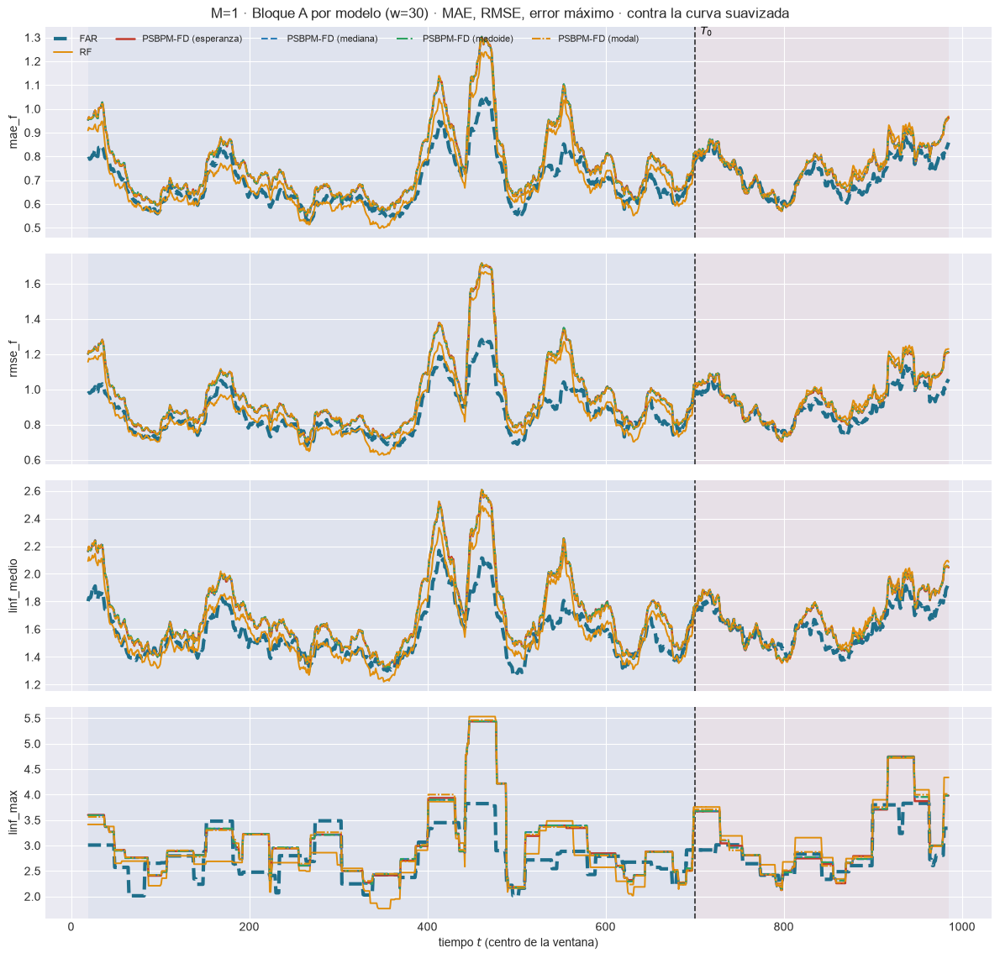

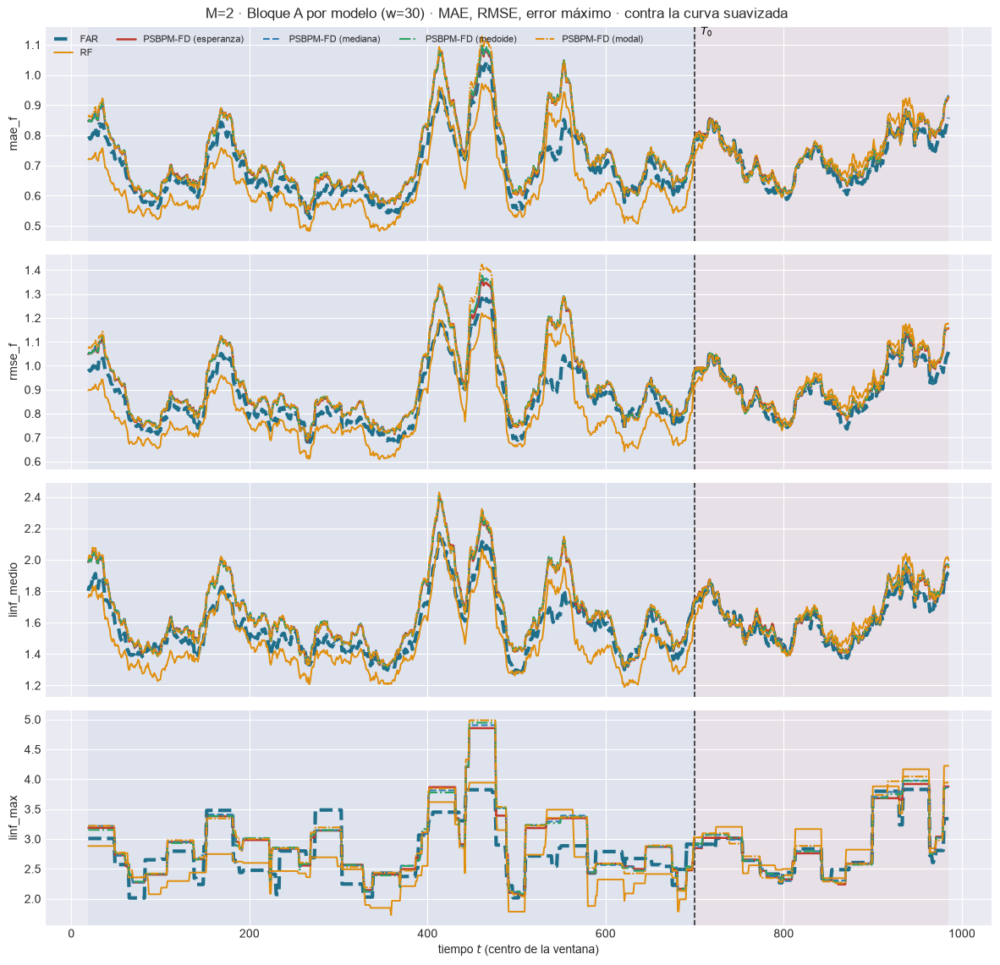

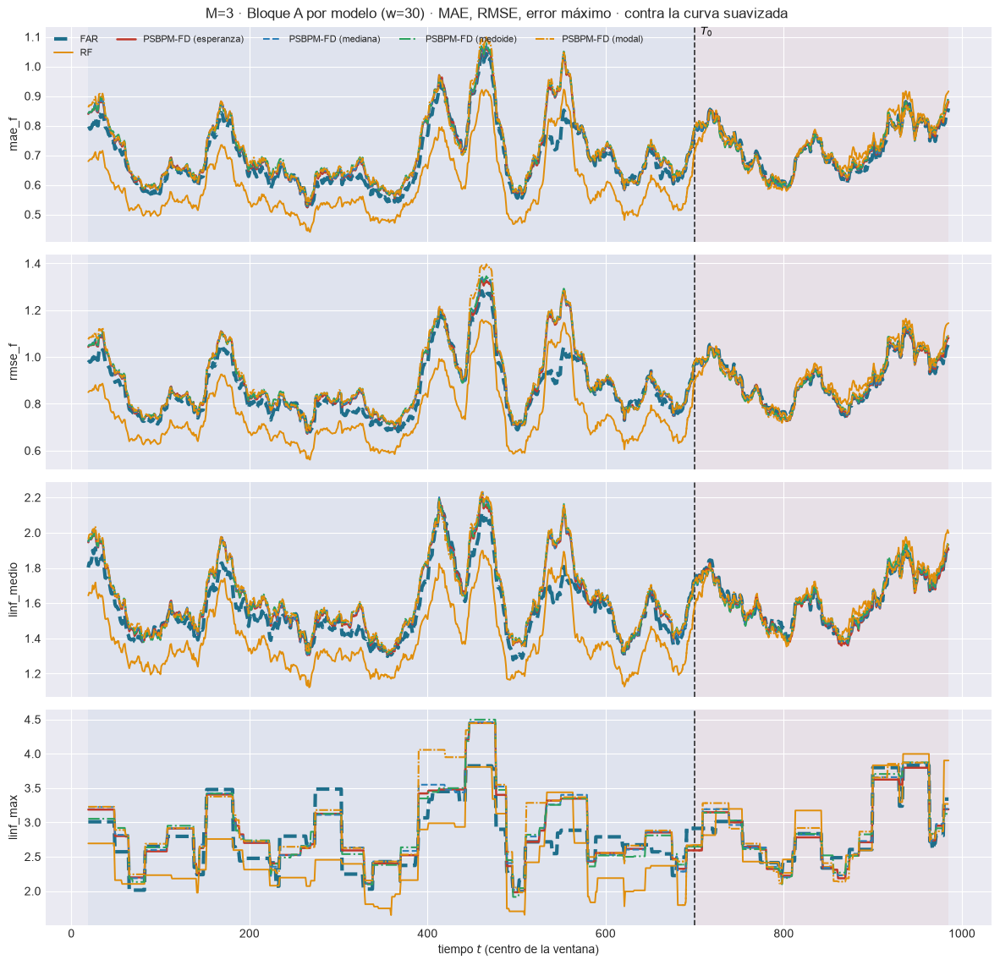

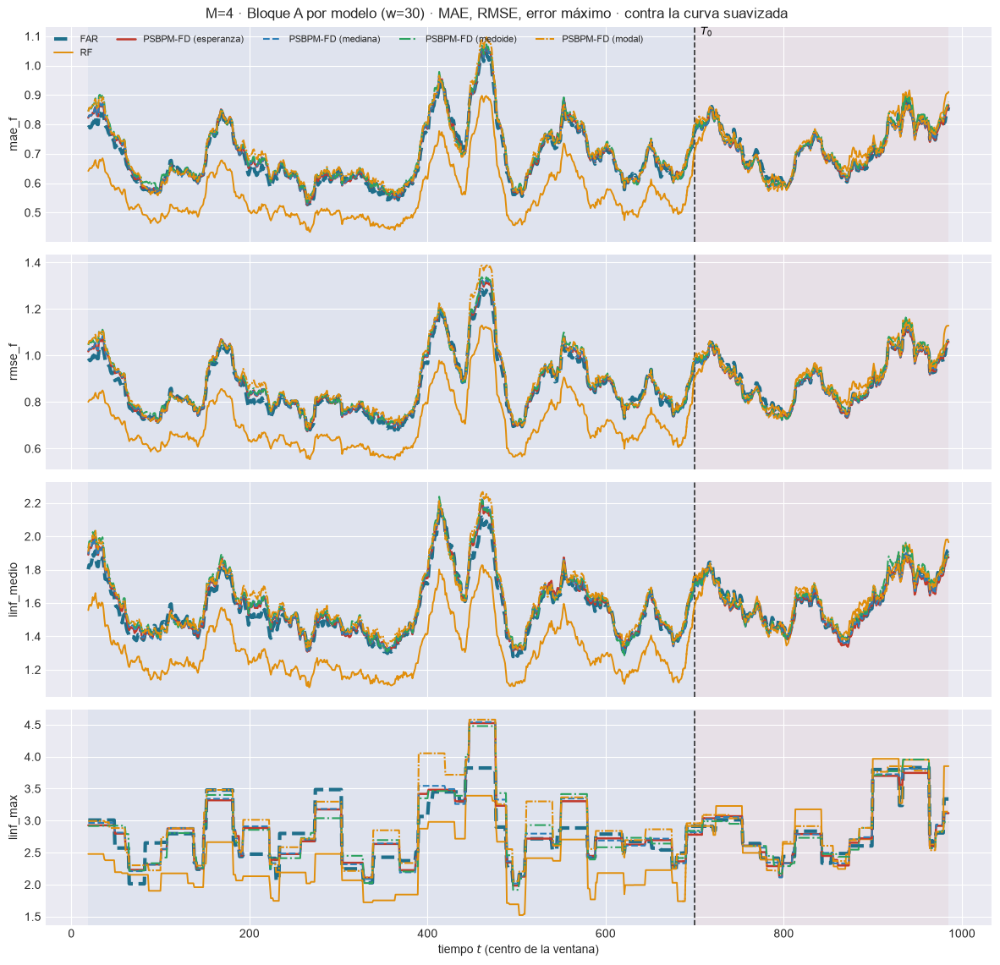

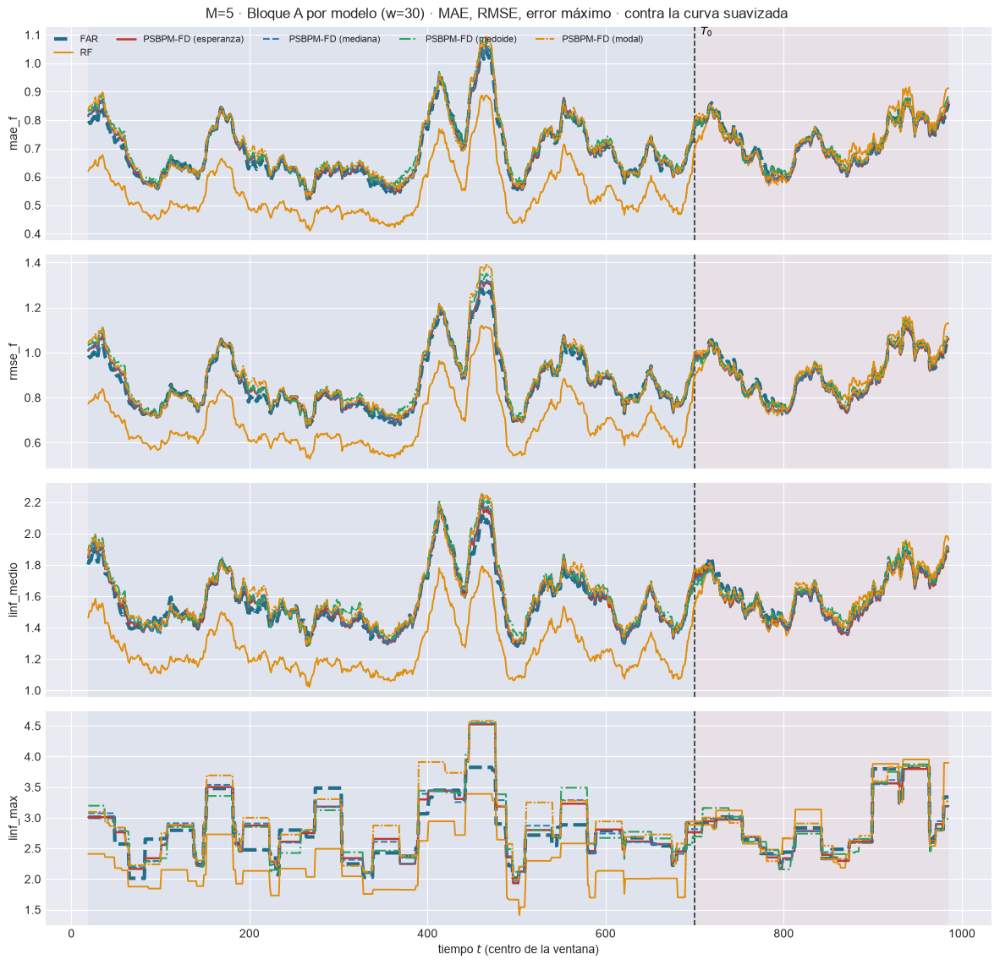

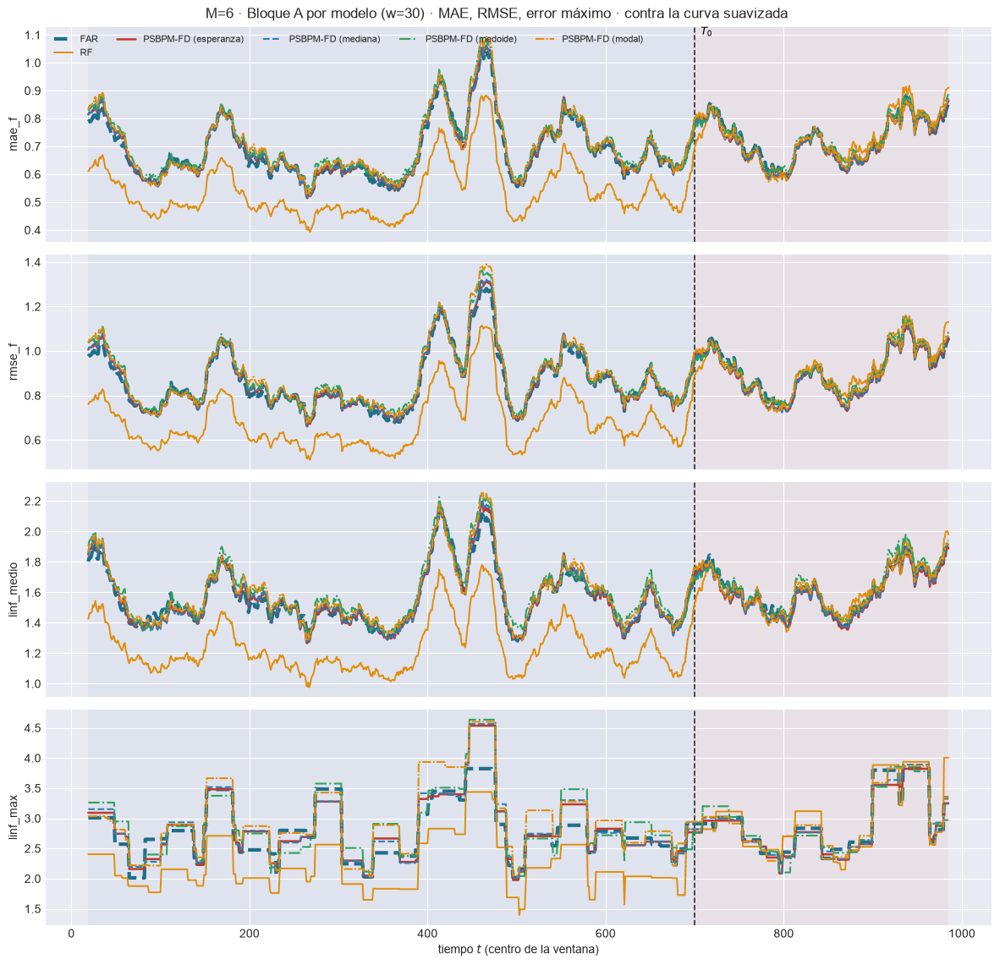

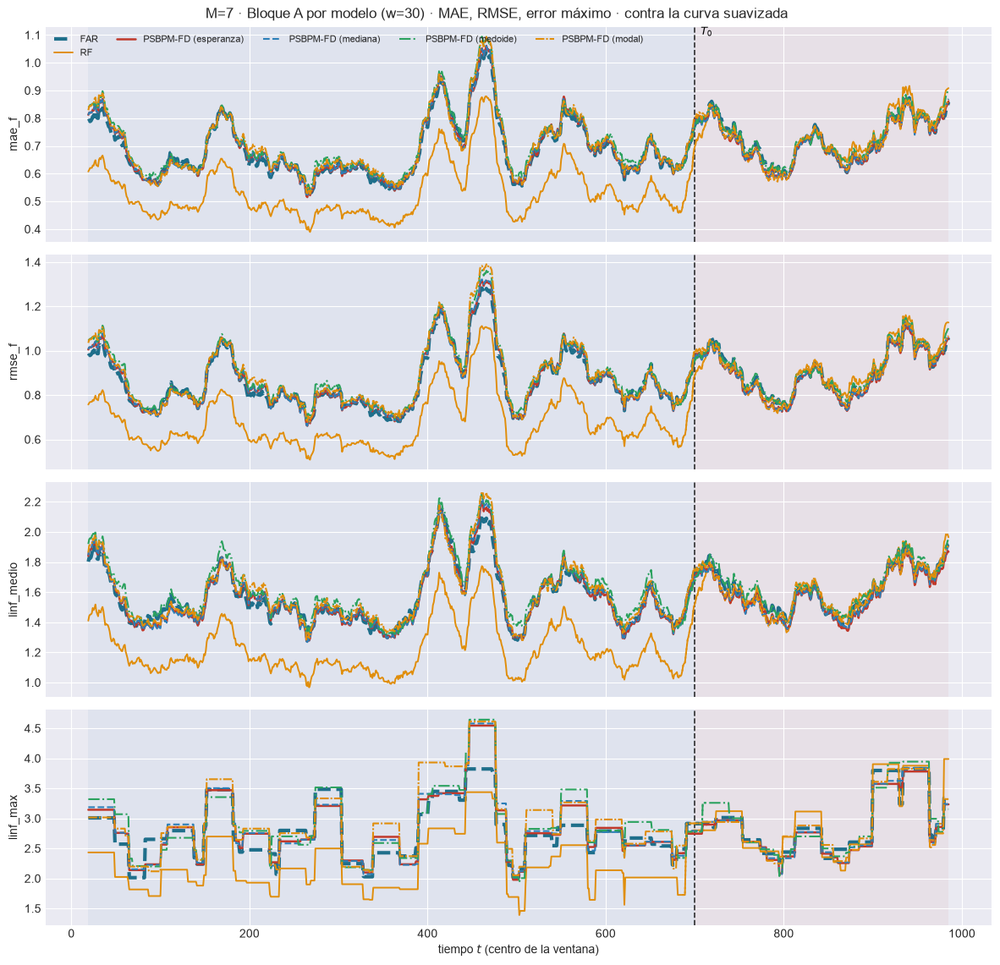

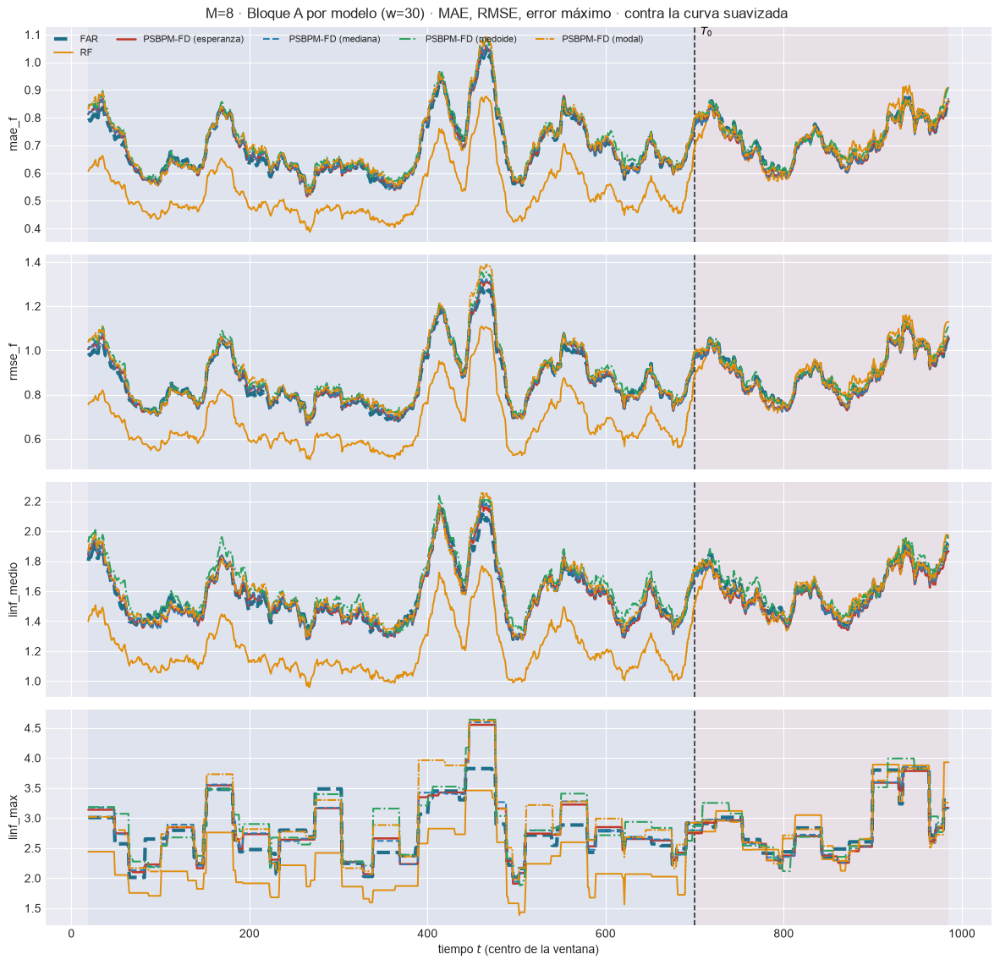

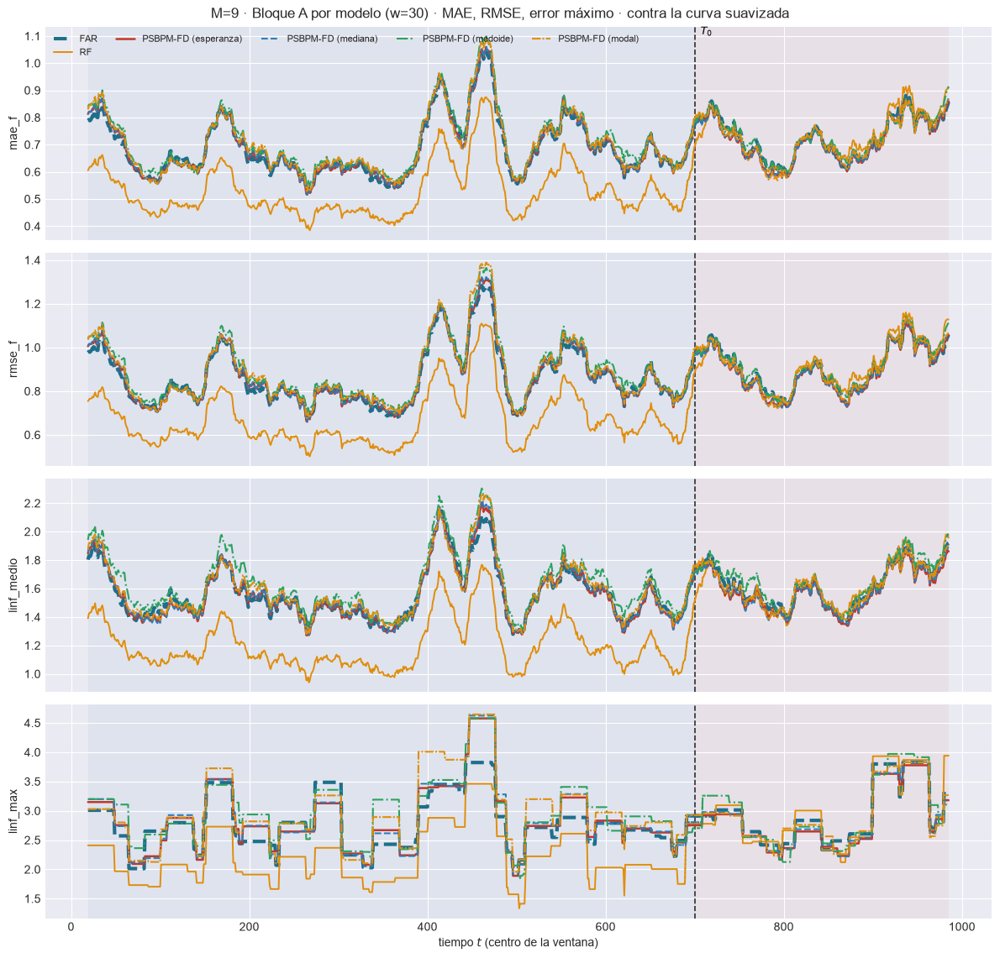

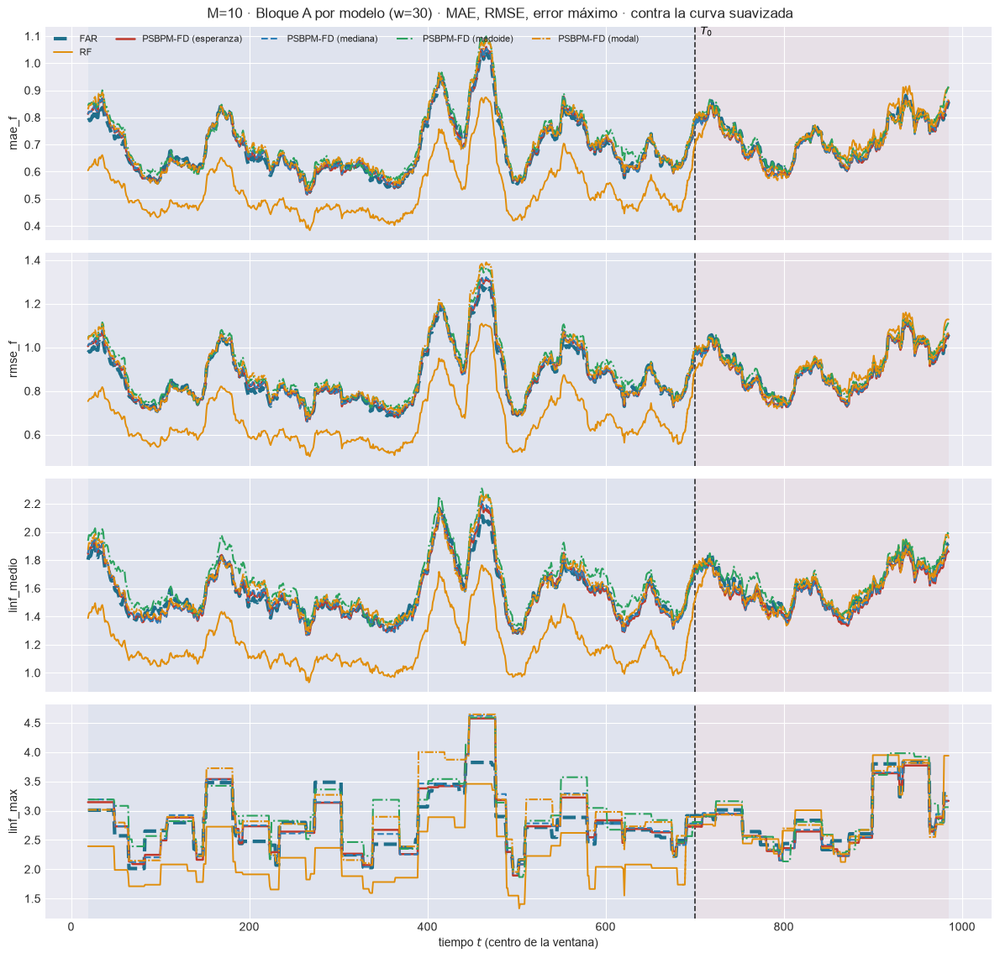

In [8]:
for M in M_OK:
    tablas_modelos(EST[M], DIS, ORIG, PESOS_TAU, PREFIJO)
verificar_cadena_modelos(EST, W_REF)

# Una figura por M; el piso de truncamiento va en las tablas pero no en la figura.
for M in M_OK:
    e = EST[M]
    tw = e["tablas_w"][W_REF]
    tf = tw[tw["modelo"] != PISO].copy()
    tf.attrs["w"] = W_REF
    plot_ventana_movil(
        tf, T0, METRICAS_A_COLS, columna_grupo="modelo", estilos=ESTILOS_MODELOS_PREDICTORES,
        title=f"M={M} · Bloque A por modelo (w={W_REF}) · MAE, RMSE, error máximo · contra la curva suavizada",
        save_path=str(e["paths"]["out_report"] / f"{PREFIJO + 8}_ventana_bloqueA_modelos_w{W_REF}.png"),
        verbose=False)
    plt.show()

## 5. Bloque B: intervalos, sólo FAR y PSBPM-FD (tres construcciones)

El RF no tiene mecanismo de intervalo propio. Del PSBPM-FD, equi-colas, simultánea y HDR con la esperanza, y el contraste misma predictiva, distinta construcción.

In [9]:
for M in M_OK:
    e = EST[M]
    construir_bandas(e, DIS, ORIG, IC_POR_TAU, IC_CORRECCION_ESTIMACION, IC_PSBP_TAMBIEN_GAUSSIANA,
                     intervalos_psbp=INTERVALOS)
    B_df = tabla_bloque_B(e, DIS, ORIG)
    display(B_df.loc["test"].style
            .format({"winkler": "{:.4f}", "picp": "{:.4f}", "ee_picp": "{:.4f}", "ace": "{:+.4f}",
                     "mpiw": "{:.4f}", "picp_simultaneo": "{:.4f}"})
            .background_gradient(subset=["winkler"], cmap="RdYlGn_r")
            .set_caption(f"M={M} · Bloque B, bloque de PRUEBA · PRIMARIA: winkler · nivel nominal {NIVEL:.0%}"))

M=1  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = -0.0191   región de máxima densidad - equi-colas = -0.0146
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.0007   región de máxima densidad - equi-colas = -0.0336


M=2  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = -0.6320   región de máxima densidad - equi-colas = -0.0458
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.3352   región de máxima densidad - equi-colas = -0.0136


M=3  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.1462   región de máxima densidad - equi-colas = -0.0274
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.6828   región de máxima densidad - equi-colas = -0.0162


M=4  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.5713   región de máxima densidad - equi-colas = -0.0146
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.8910   región de máxima densidad - equi-colas = -0.0042


M=5  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.8113   región de máxima densidad - equi-colas = -0.0064
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.9359   región de máxima densidad - equi-colas = -0.0034


M=6  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.9182   región de máxima densidad - equi-colas = -0.0013
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.9902   región de máxima densidad - equi-colas = +0.0003


M=7  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.9994   región de máxima densidad - equi-colas = -0.0004
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +1.0270   región de máxima densidad - equi-colas = +0.0050


M=8  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +1.0324   región de máxima densidad - equi-colas = -0.0019
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +1.0476   región de máxima densidad - equi-colas = +0.0022


M=9  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +1.0597   región de máxima densidad - equi-colas = -0.0027
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +1.0603   región de máxima densidad - equi-colas = -0.0005


M=10  kn=5  correccion=1.0036  sigma_eps(tau) del FAR: min=0.7566 max=0.9232 (razon 1.22)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +1.0644   región de máxima densidad - equi-colas = -0.0029
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +1.0644   región de máxima densidad - equi-colas = -0.0029


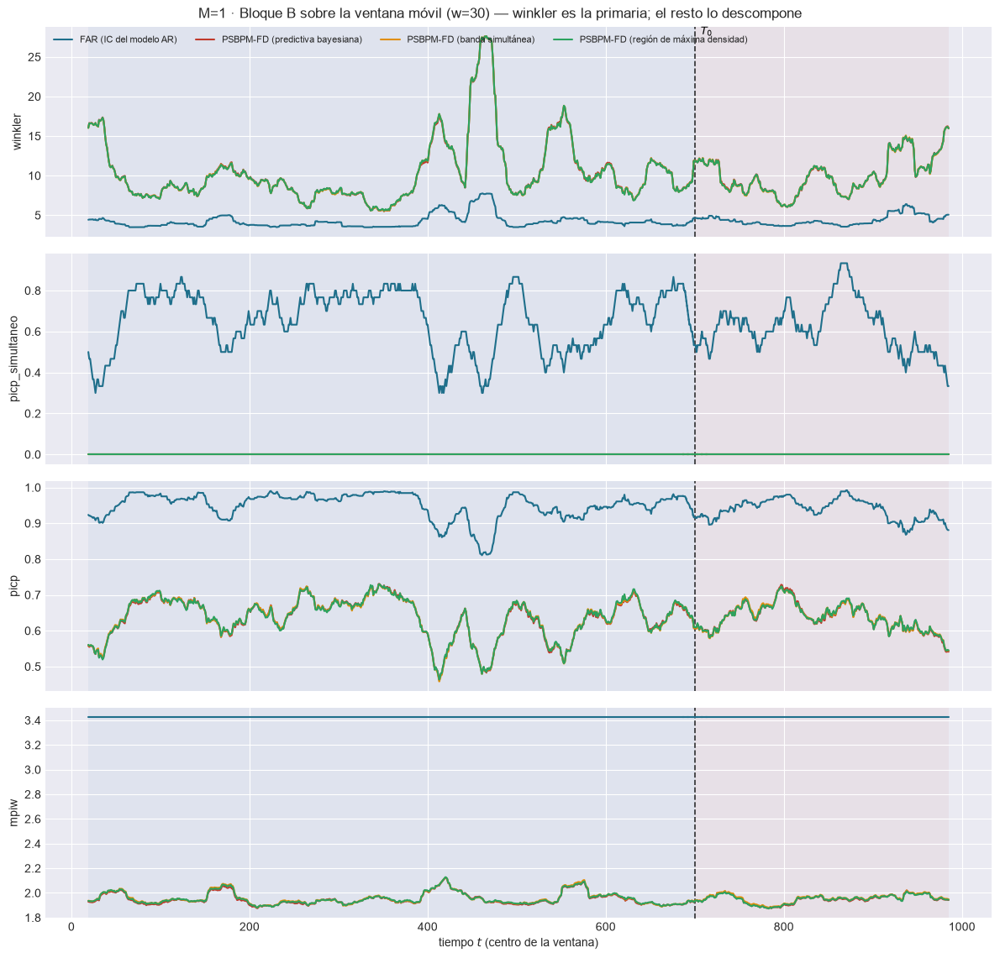

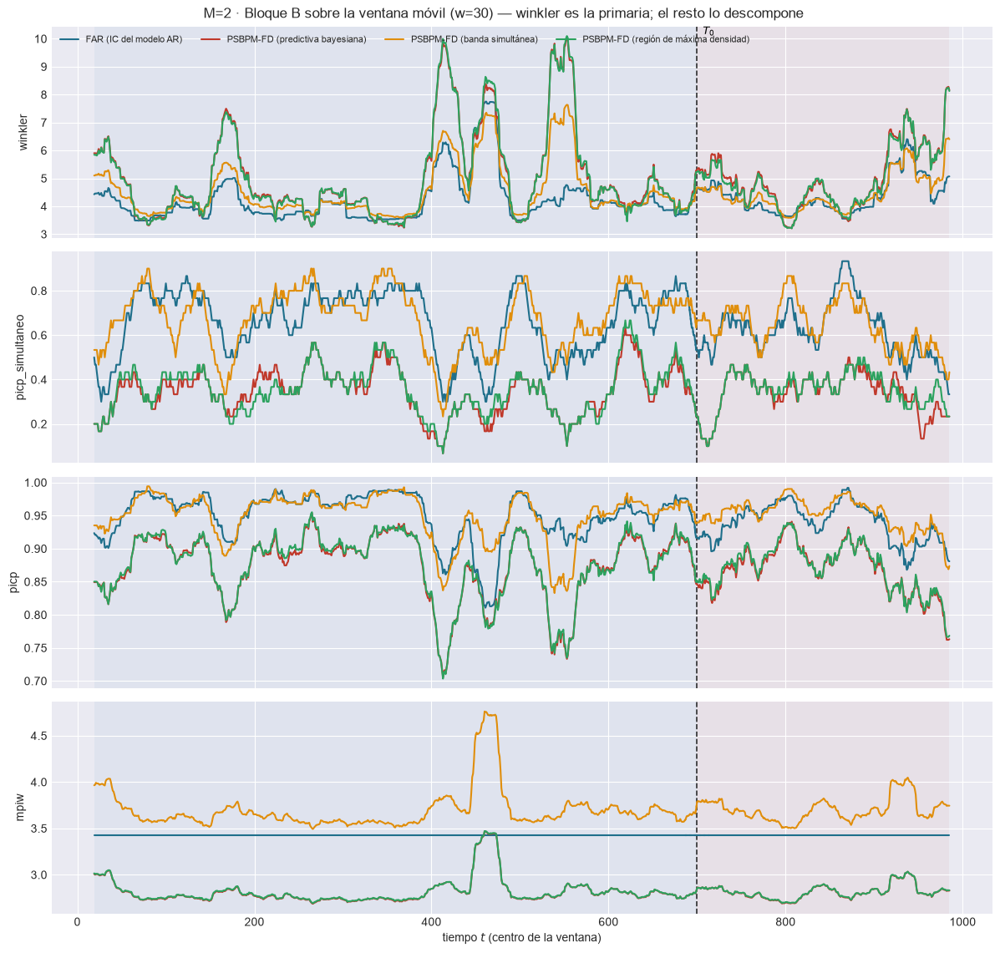

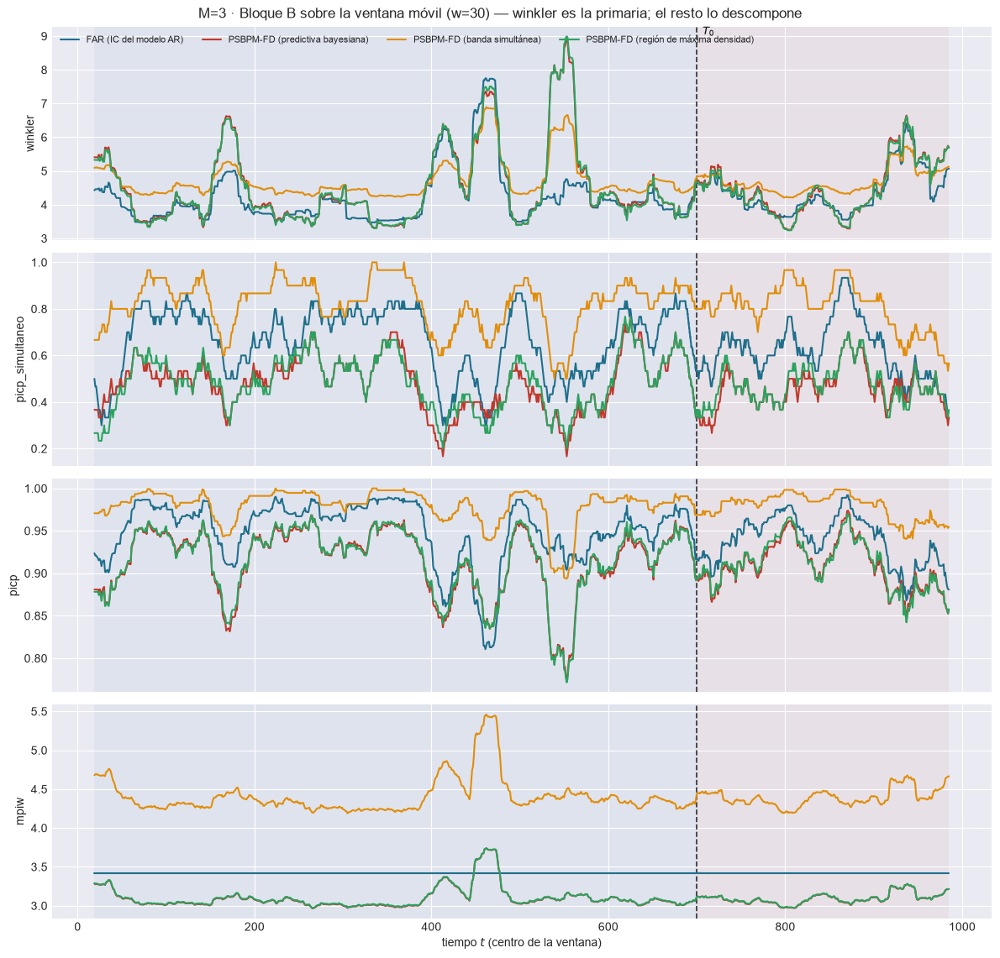

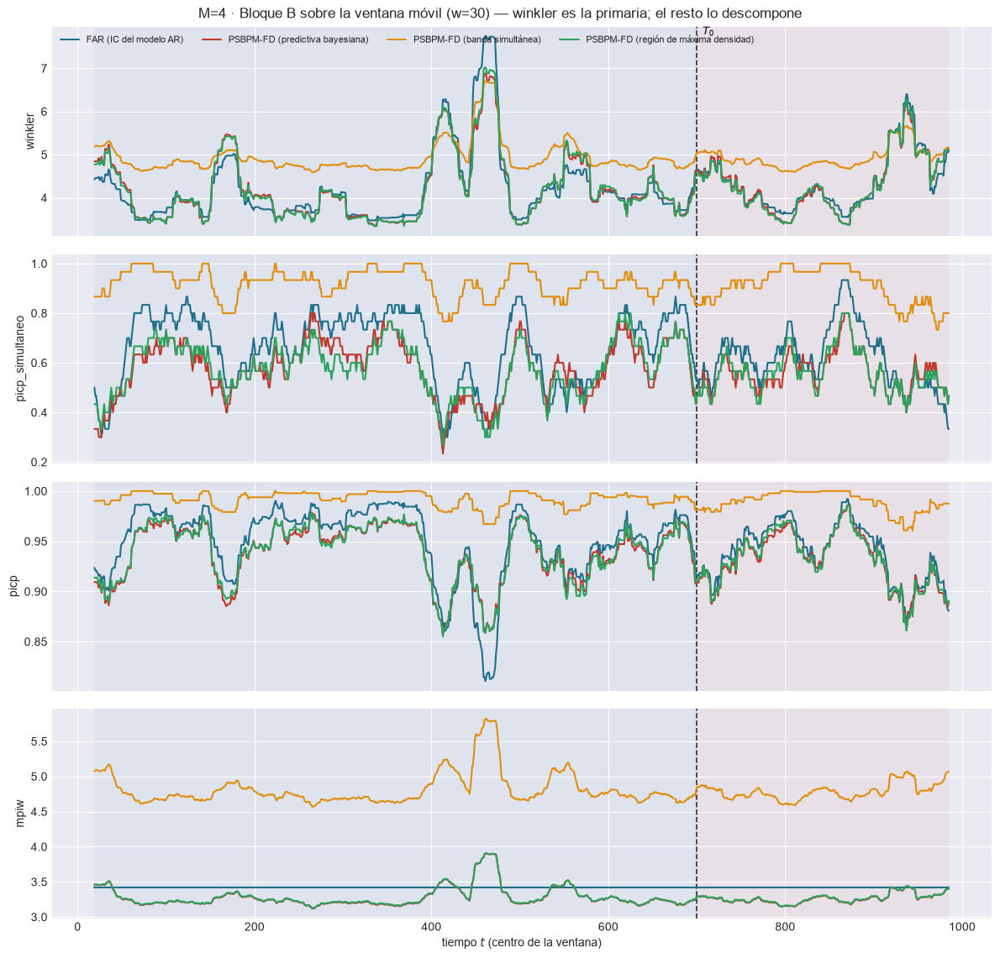

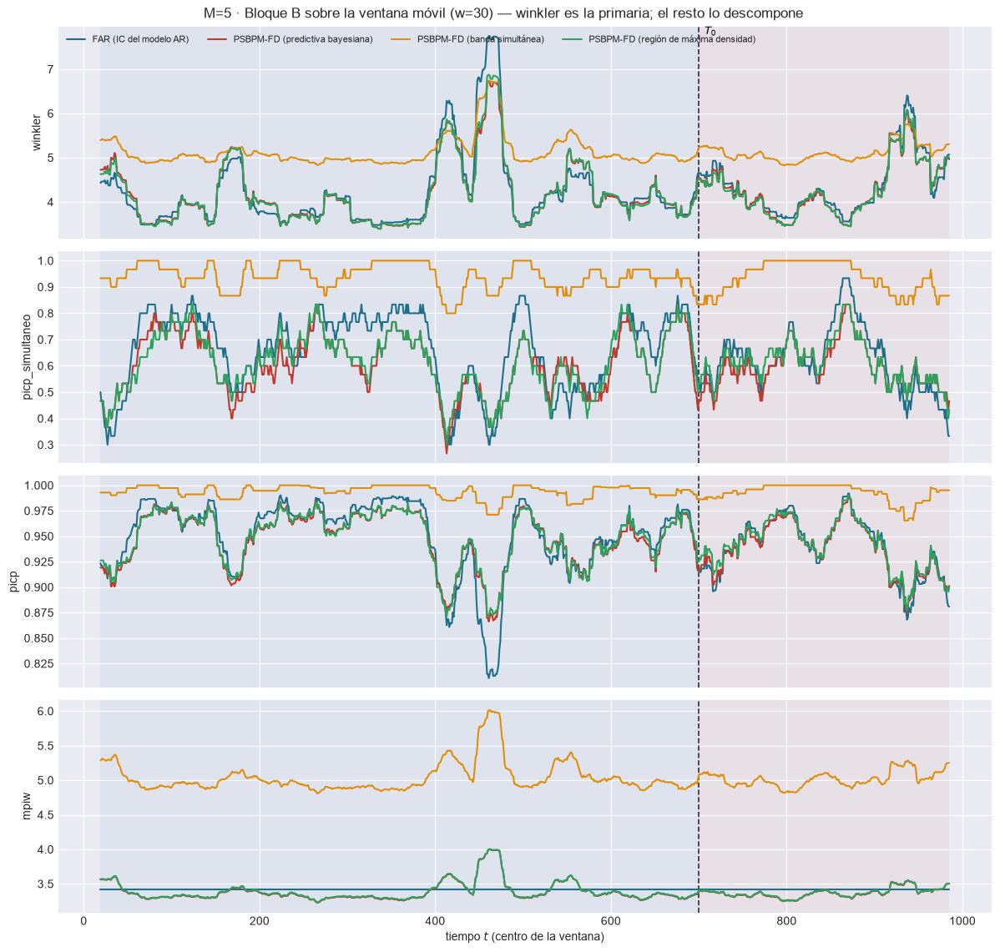

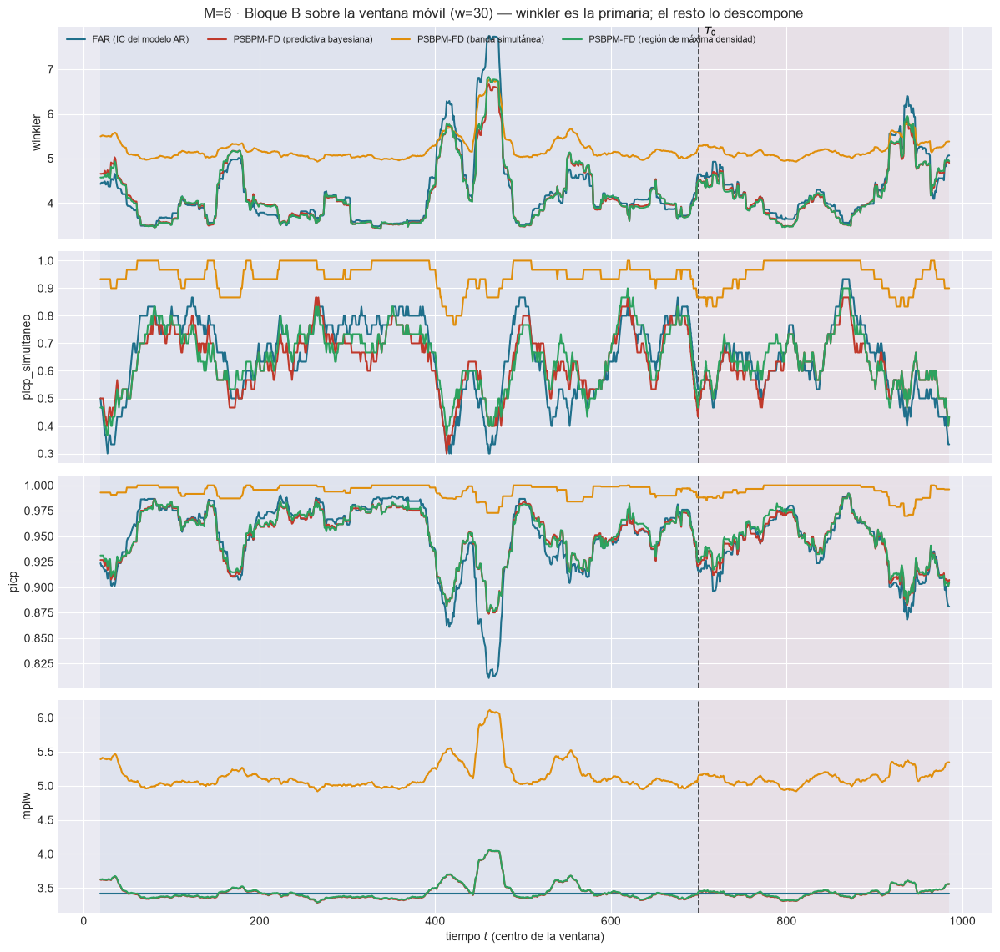

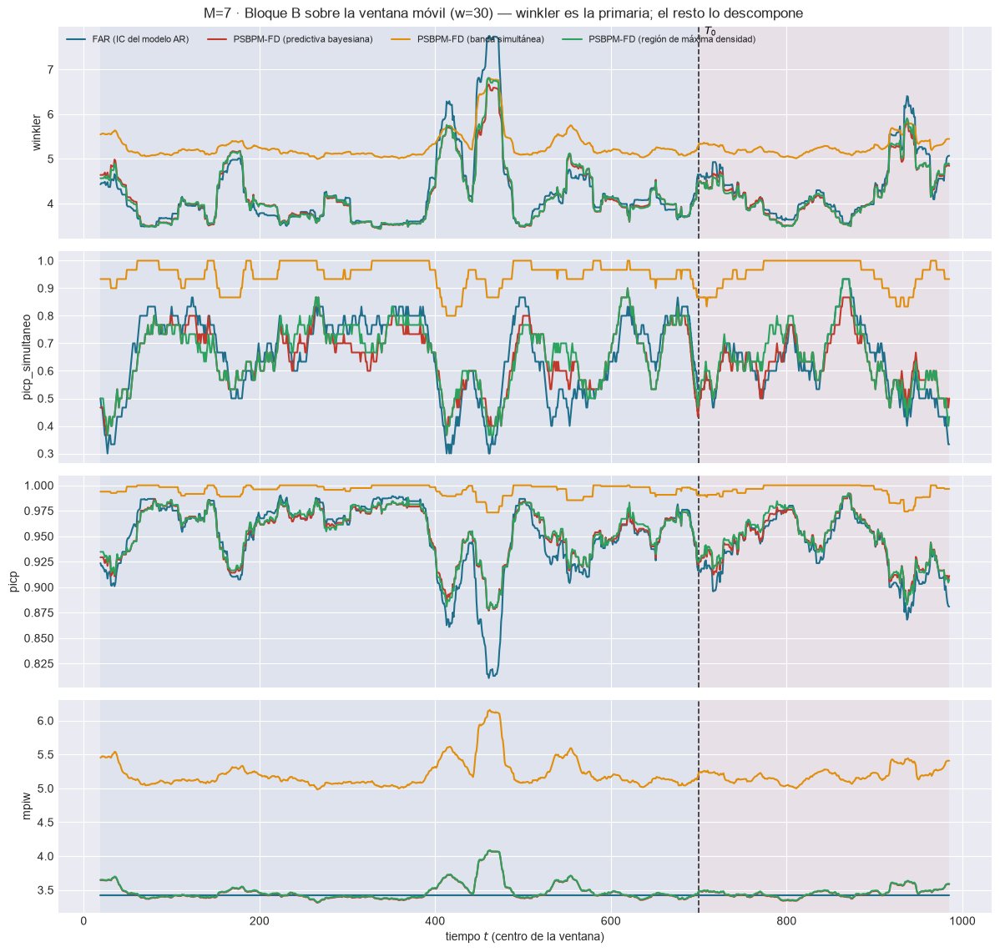

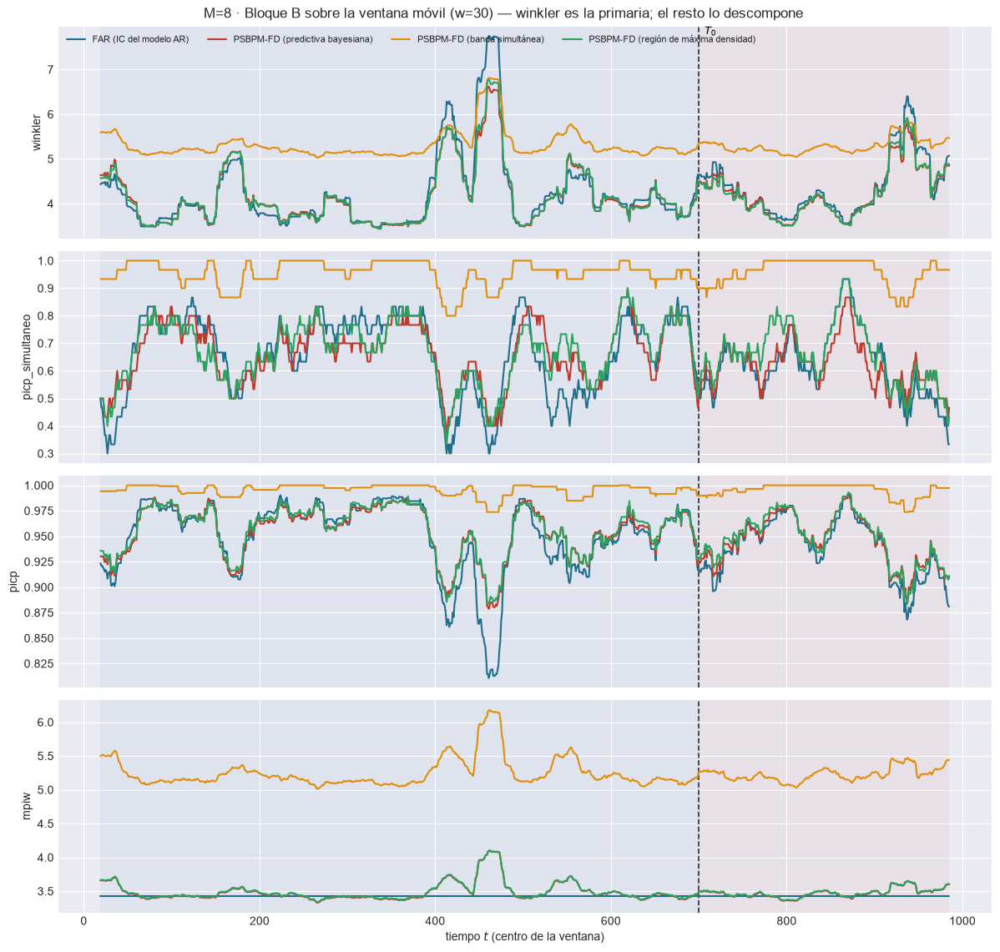

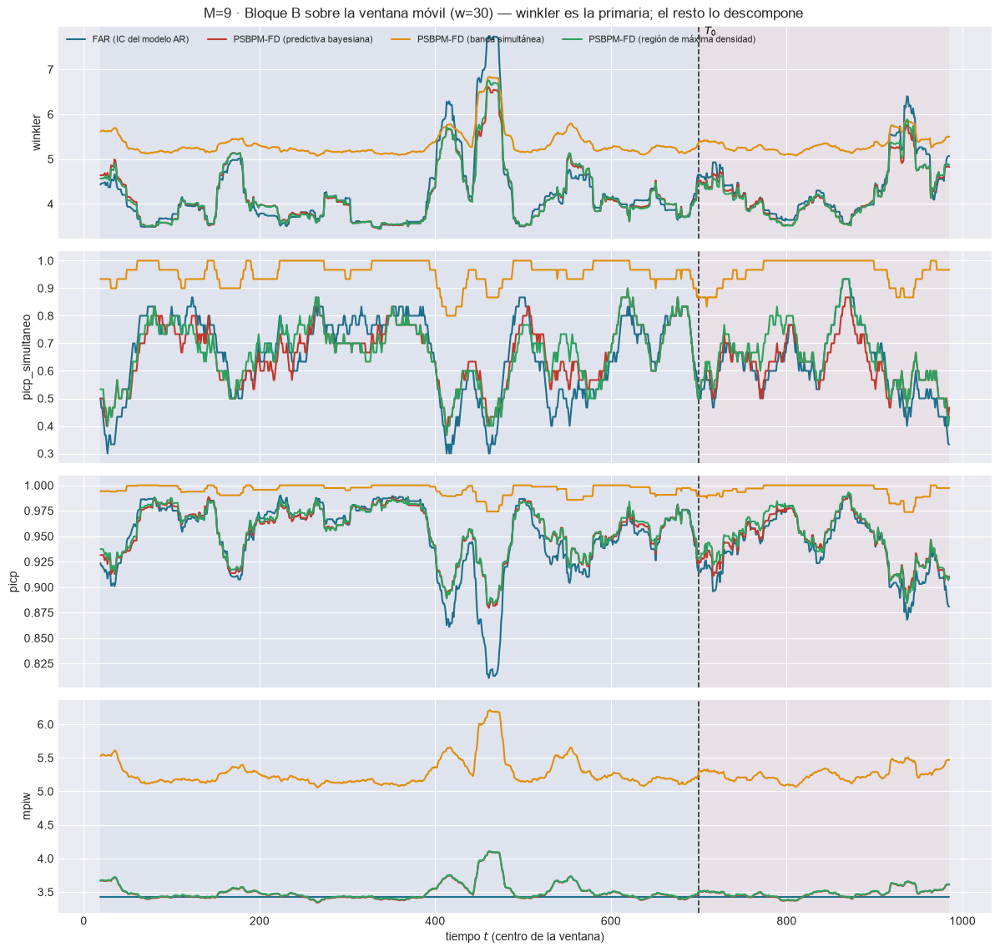

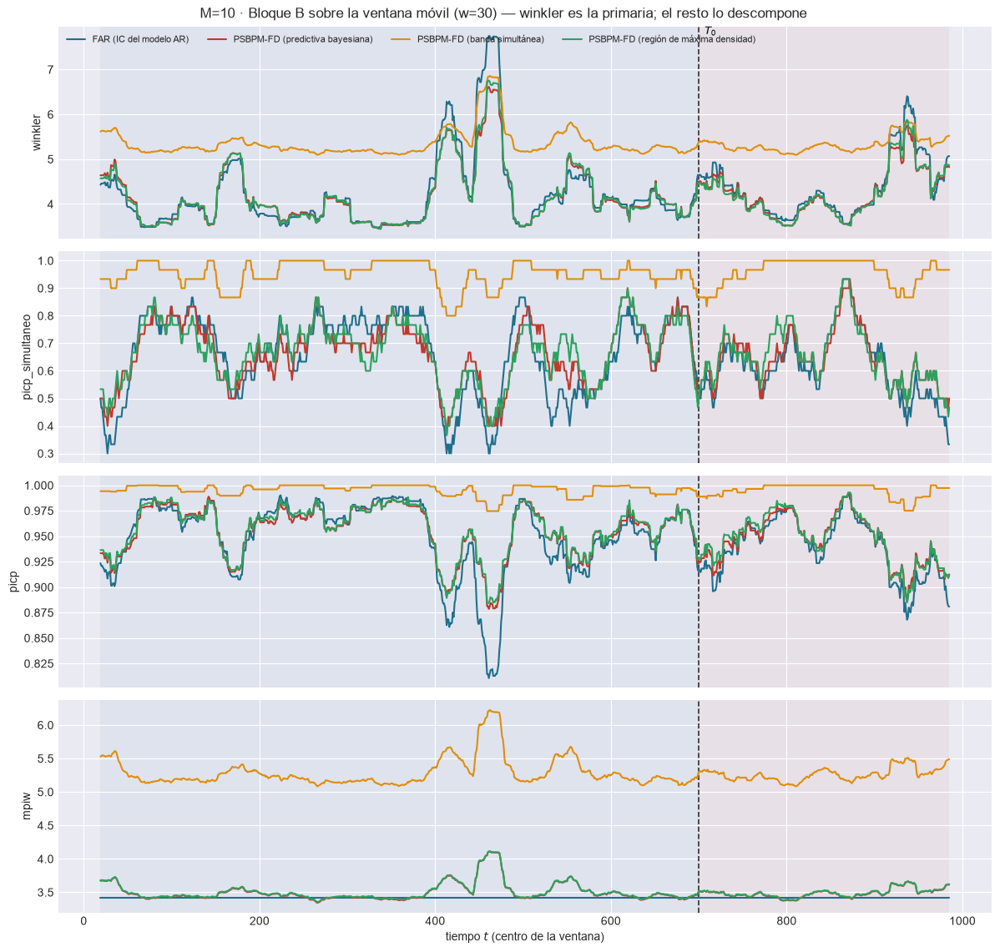

In [10]:
# Winkler sobre la ventana móvil y su descomposición: dice CUÁNDO falla la banda, no sólo cuánto.
for M in M_OK:
    e = EST[M]
    vb = ventana_bloque_B(e, DIS, ORIG, PESOS_TAU, PREFIJO)
    plot_ventana_movil(
        vb, T0, ["winkler", "picp_simultaneo", "picp", "mpiw"], columna_grupo="banda", estilos=ESTILOS_BANDAS,
        title=f"M={M} · Bloque B sobre la ventana móvil (w={W_REF}) — winkler es la primaria; el resto lo descompone",
        save_path=str(e["paths"]["out_report"] / f"81_ventana_bloqueB_w{W_REF}.png"), verbose=False)
    plt.show()

## 6. Bloque A: quién gana cada ventana, y por cuánto

% de ventanas ganadas y razón contra el mejor y contra el FAR, sin las ventanas que cruzan $T_0$.

M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,77.9%,66.8%,42.4%,25.5%,17.3%,13.7%,11.8%,12.2%,11.4%,11.4%
PSBPM-FD (esperanza),9.6%,3.7%,3.0%,24.4%,21.4%,24.4%,29.5%,28.8%,27.3%,28.4%
PSBPM-FD (mediana),0.0%,4.8%,8.9%,17.7%,29.2%,32.8%,27.3%,30.3%,33.9%,31.0%
PSBPM-FD (medoide),4.1%,7.7%,16.2%,4.8%,3.0%,1.5%,5.9%,5.5%,3.3%,5.2%
PSBPM-FD (modal),3.0%,12.5%,21.8%,16.6%,17.0%,17.0%,17.0%,17.3%,18.1%,18.1%
RF,5.5%,4.4%,7.7%,11.1%,12.2%,10.7%,8.5%,5.9%,5.9%,5.9%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.005,1.005,1.013,1.016,1.019,1.019,1.020,1.021,1.021,1.021
PSBPM-FD (esperanza),1.047,1.027,1.013,1.006,1.005,1.004,1.004,1.004,1.004,1.004
PSBPM-FD (mediana),1.049,1.027,1.013,1.007,1.005,1.005,1.005,1.004,1.004,1.004
PSBPM-FD (medoide),1.049,1.026,1.016,1.019,1.022,1.027,1.032,1.031,1.031,1.030
PSBPM-FD (modal),1.049,1.027,1.016,1.014,1.013,1.012,1.012,1.011,1.011,1.011
RF,1.060,1.046,1.035,1.031,1.032,1.031,1.033,1.034,1.035,1.035


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,76.8%,72.3%,43.5%,20.3%,12.2%,8.5%,7.7%,7.4%,7.0%,6.6%
PSBPM-FD (esperanza),11.1%,7.4%,16.2%,43.9%,45.8%,47.6%,53.1%,51.3%,53.5%,56.1%
PSBPM-FD (mediana),3.0%,2.2%,4.1%,16.2%,28.0%,28.0%,23.6%,28.8%,27.3%,25.1%
PSBPM-FD (medoide),3.7%,3.7%,20.3%,7.0%,1.1%,3.3%,3.3%,0.4%,0.0%,0.0%
PSBPM-FD (modal),4.8%,11.1%,12.2%,9.2%,9.2%,8.9%,8.9%,8.9%,8.9%,8.9%
RF,0.7%,3.3%,3.7%,3.3%,3.7%,3.7%,3.3%,3.3%,3.3%,3.3%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.004,1.004,1.012,1.016,1.018,1.019,1.020,1.020,1.020,1.021
PSBPM-FD (esperanza),1.052,1.023,1.008,1.003,1.003,1.003,1.002,1.002,1.002,1.002
PSBPM-FD (mediana),1.054,1.024,1.009,1.005,1.004,1.004,1.004,1.003,1.003,1.003
PSBPM-FD (medoide),1.054,1.025,1.012,1.016,1.022,1.026,1.031,1.031,1.031,1.031
PSBPM-FD (modal),1.055,1.025,1.014,1.014,1.014,1.014,1.014,1.014,1.014,1.014
RF,1.070,1.046,1.035,1.033,1.035,1.035,1.036,1.037,1.037,1.037


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,78.6%,70.5%,29.2%,20.7%,5.5%,2.6%,3.0%,1.8%,1.8%,1.1%
PSBPM-FD (esperanza),5.2%,7.7%,26.9%,35.1%,41.7%,49.4%,48.3%,49.1%,54.6%,54.2%
PSBPM-FD (mediana),0.0%,0.7%,7.4%,12.5%,18.8%,18.8%,22.9%,20.7%,19.9%,22.9%
PSBPM-FD (medoide),4.8%,8.1%,8.9%,2.2%,1.8%,0.7%,0.0%,0.4%,0.0%,0.0%
PSBPM-FD (modal),0.7%,6.3%,12.2%,15.9%,18.1%,11.8%,9.2%,12.5%,8.5%,8.5%
RF,10.7%,6.6%,15.5%,13.7%,14.0%,16.6%,16.6%,15.5%,15.1%,13.3%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.006,1.004,1.012,1.015,1.019,1.021,1.024,1.025,1.026,1.026
PSBPM-FD (esperanza),1.040,1.022,1.007,1.005,1.004,1.003,1.003,1.003,1.003,1.003
PSBPM-FD (mediana),1.041,1.022,1.009,1.007,1.005,1.006,1.005,1.005,1.005,1.005
PSBPM-FD (medoide),1.041,1.022,1.011,1.023,1.026,1.036,1.041,1.045,1.049,1.051
PSBPM-FD (modal),1.042,1.021,1.015,1.019,1.018,1.020,1.021,1.021,1.021,1.021
RF,1.047,1.036,1.022,1.022,1.023,1.022,1.023,1.022,1.024,1.024


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,69.0%,33.9%,17.3%,16.6%,5.5%,2.6%,6.6%,4.1%,4.1%,8.1%
PSBPM-FD (esperanza),21.4%,25.5%,36.9%,23.6%,22.9%,18.1%,26.9%,29.9%,43.9%,42.1%
PSBPM-FD (mediana),1.8%,4.1%,1.5%,1.5%,6.3%,1.8%,6.3%,1.8%,4.4%,0.7%
PSBPM-FD (medoide),0.0%,9.6%,8.5%,33.6%,26.9%,33.2%,19.9%,22.9%,14.4%,14.4%
PSBPM-FD (modal),6.6%,19.6%,17.0%,7.7%,12.5%,16.6%,22.1%,23.6%,15.5%,21.0%
RF,1.1%,7.4%,18.8%,17.0%,25.8%,27.7%,18.1%,17.7%,17.7%,13.7%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.014,1.025,1.041,1.036,1.041,1.048,1.045,1.051,1.053,1.052
PSBPM-FD (esperanza),1.075,1.025,1.030,1.028,1.024,1.027,1.019,1.021,1.019,1.019
PSBPM-FD (mediana),1.078,1.032,1.037,1.035,1.031,1.034,1.024,1.026,1.026,1.025
PSBPM-FD (medoide),1.078,1.031,1.043,1.036,1.032,1.045,1.054,1.052,1.058,1.060
PSBPM-FD (modal),1.082,1.040,1.046,1.052,1.048,1.053,1.042,1.043,1.042,1.042
RF,1.120,1.081,1.061,1.071,1.066,1.070,1.064,1.064,1.064,1.067


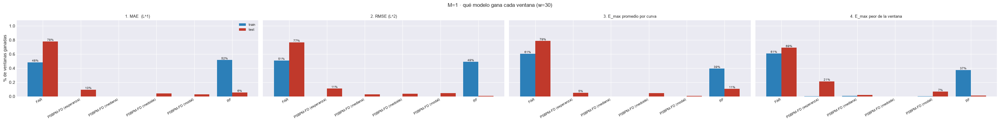

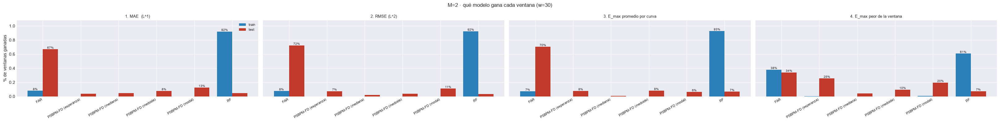

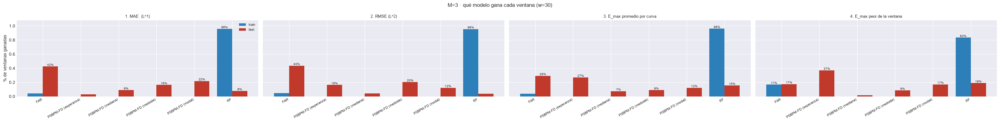

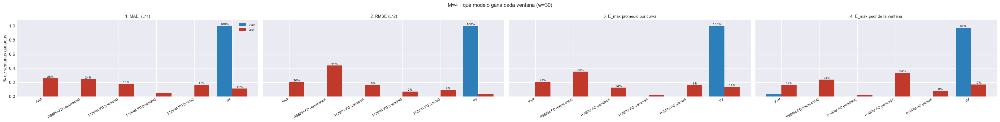

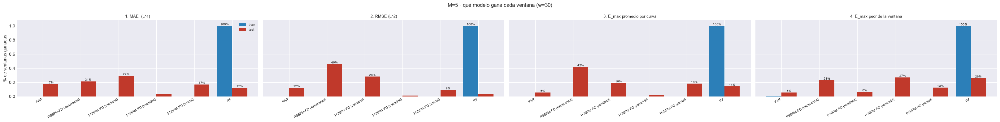

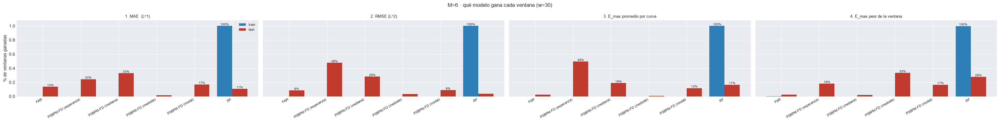

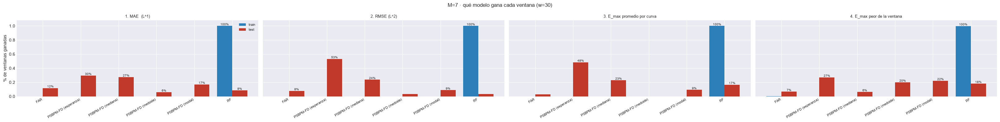

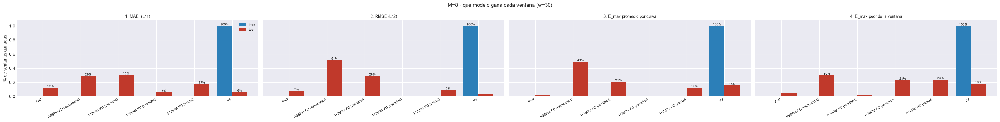

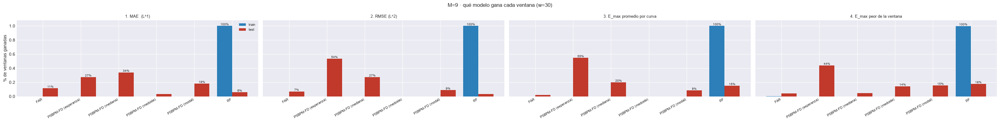

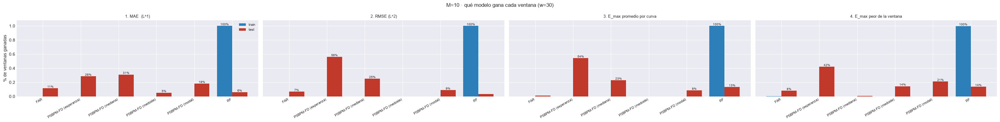

In [11]:
gana_A, rel_A = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO,))
gana_A.to_csv(PATH_BARRIDO / "96_ganador_ventana_bloqueA.csv", index=False)
rel_A.to_csv(PATH_BARRIDO / "96_razones_bloqueA.csv", index=False)

for etiqueta, _col in METRICAS_A:
    for tabla, v, fmt, cmap, cap in (
            (gana_A, "pct_ventanas_ganadas", "{:.1%}", "RdYlGn",
             f"{etiqueta} · % de ventanas de PRUEBA ganadas (w={W_REF}, sin cruzar T0)"),
            (rel_A, "razon_vs_mejor", "{:.3f}", "RdYlGn_r",
             f"{etiqueta} · razón contra el MEJOR de cada ventana (test) · 1.000 = gana siempre")):
        piv = (tabla[(tabla.metrica == etiqueta) & (tabla.bloque == "test")]
               .pivot(index="modelo", columns="M", values=v))
        display(piv.style.format(fmt, na_rep="-").background_gradient(cmap=cmap, axis=None).set_caption(cap))

for M in M_OK:
    plot_ganador_modelo(gana_A, M, METRICAS_A, W_REF,
                        EST[M]["paths"]["out_report"] / f"{PREFIJO + 8}_ganador_ventana_bloqueA.png")
    plt.show()

In [12]:
# Cada predictor del PSBPM-FD contra FAR y RF por separado (106_ganador_psbp_por_predictor.csv).
partes = []
for p in PREDICTORES:
    otros = [nombre_psbp(q) for q in PREDICTORES if q != p]
    g, _ = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO, *otros))
    partes.append(g[g.modelo == nombre_psbp(p)].assign(predictor=p))
gana_P = pd.concat(partes, ignore_index=True)
gana_P.to_csv(PATH_BARRIDO / "106_ganador_psbp_por_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(gana_P[(gana_P.metrica == etiqueta) & (gana_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST que gana el PSBPM-FD con cada predictor, contra FAR y RF"))

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,16.6%,18.1%,38.4%,58.3%,66.1%,70.8%,76.0%,78.6%,79.3%,79.3%
mediana,15.9%,22.1%,44.3%,55.0%,65.3%,69.4%,73.8%,76.8%,76.4%,76.0%
medoide,15.9%,21.8%,41.7%,28.0%,24.4%,14.4%,14.4%,25.8%,25.8%,29.5%
modal,14.0%,25.8%,39.1%,39.9%,43.2%,46.1%,48.0%,49.8%,51.7%,51.7%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,22.1%,22.1%,46.5%,74.9%,82.3%,86.7%,87.8%,88.6%,88.9%,89.3%
mediana,21.0%,21.0%,43.9%,65.3%,78.2%,80.1%,83.0%,83.8%,84.1%,83.4%
medoide,21.0%,20.3%,43.5%,34.3%,22.9%,20.3%,13.3%,20.3%,17.3%,17.0%
modal,20.3%,21.4%,31.7%,43.5%,47.6%,49.1%,50.9%,51.3%,52.0%,52.0%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,10.3%,17.3%,39.5%,56.8%,68.6%,75.6%,74.5%,76.0%,79.3%,78.6%
mediana,7.7%,15.5%,39.1%,55.7%,71.6%,74.2%,76.8%,77.1%,76.8%,78.2%
medoide,7.7%,16.2%,31.0%,20.3%,12.9%,10.3%,4.1%,8.1%,2.2%,0.7%
modal,8.5%,15.9%,21.8%,30.3%,31.0%,28.0%,32.1%,34.3%,39.5%,43.5%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,29.9%,50.6%,61.3%,49.4%,59.8%,64.9%,72.0%,72.3%,72.3%,71.6%
mediana,29.9%,56.1%,48.7%,50.2%,49.4%,53.9%,60.9%,62.0%,61.3%,74.2%
medoide,29.9%,46.9%,41.3%,52.4%,39.9%,36.5%,38.0%,39.5%,32.1%,35.1%
modal,18.8%,42.8%,32.8%,24.0%,32.1%,28.4%,48.7%,56.5%,67.5%,67.5%


## 7. Bloque B: quién gana cada ventana, y por cuánto

Lo mismo sobre las bandas; el Winkler decide.

In [13]:
# En picp / picp_simultaneo "ganar" es estar más cerca del nominal, no tener el valor más bajo.
gana_B, rel_B = ganadores_por_ventana(EST, "ventana_B", "banda", METRICAS_B, NIVEL)
gana_B.to_csv(PATH_BARRIDO / "97_ganador_ventana_bloqueB.csv", index=False)
rel_B.to_csv(PATH_BARRIDO / "97_razones_bloqueB.csv", index=False)

for etiqueta, col in METRICAS_B:
    piv = (gana_B[(gana_B.metrica == etiqueta) & (gana_B.bloque == "test")]
           .pivot(index="banda", columns="M", values="pct_ventanas_ganadas"))
    crit = "más cerca del nominal" if col.startswith("picp") else "menor es mejor"
    display(piv.style.format("{:.1%}", na_rep="-").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas de PRUEBA ganadas (criterio: {crit})"))

M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),0.0%,0.0%,0.0%,1.8%,14.8%,46.5%,67.5%,77.5%,85.2%,88.2%
PSBPM-FD (banda simultánea),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),55.0%,92.3%,98.9%,98.2%,85.2%,53.5%,32.5%,22.5%,14.8%,11.8%
PSBPM-FD (región de máxima densidad),45.0%,7.7%,1.1%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,38.7%,45.0%,36.9%,18.8%,26.2%,29.5%,35.1%,32.8%,35.8%
PSBPM-FD (banda simultánea),0.0%,54.2%,30.3%,26.9%,17.3%,11.1%,10.0%,10.3%,10.3%,10.0%
PSBPM-FD (predictiva bayesiana),0.0%,4.8%,13.3%,24.0%,38.7%,34.3%,41.3%,32.8%,35.1%,33.9%
PSBPM-FD (región de máxima densidad),0.0%,2.2%,11.4%,12.2%,25.1%,28.4%,19.2%,21.8%,21.8%,20.3%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,46.5%,3.0%,4.4%,4.4%,4.4%,4.4%,4.4%,4.4%,4.1%
PSBPM-FD (banda simultánea),0.0%,53.5%,97.0%,95.6%,95.6%,95.6%,95.6%,95.6%,95.6%,95.6%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.4%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,52.8%,52.0%,21.4%,15.5%,12.2%,10.3%,9.6%,8.9%,10.7%
PSBPM-FD (banda simultánea),0.0%,38.7%,17.7%,10.3%,3.3%,1.5%,0.4%,0.0%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),0.0%,2.6%,16.2%,15.5%,30.3%,36.5%,37.3%,36.2%,32.1%,35.4%
PSBPM-FD (región de máxima densidad),0.0%,5.9%,14.0%,52.8%,50.9%,49.8%,52.0%,54.2%,59.0%,53.9%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,42.4%,3.7%,3.0%,3.0%,3.0%,2.2%,2.2%,0.0%,0.0%
PSBPM-FD (banda simultánea),0.0%,57.6%,96.3%,97.0%,95.9%,93.0%,91.1%,90.8%,90.8%,90.8%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.4%,0.0%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.0%,1.1%,4.1%,6.3%,7.0%,9.2%,9.2%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,38.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),0.0%,61.6%,98.5%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,1.5%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


## 8. Cuadro resumen: mínimo, máximo y promedio

Por modelo, métrica y bloque, sin las ventanas que cruzan $T_0$.

In [14]:
resumen_A = resumen_min_max(EST, "ventana_df", "modelo", METRICAS_A, excluir=(PISO,))
resumen_B = resumen_min_max(EST, "ventana_B", "banda", METRICAS_B)
resumen_A.to_csv(PATH_BARRIDO / "98_resumen_bloqueA_min_max_prom.csv", index=False)
resumen_B.to_csv(PATH_BARRIDO / "99_resumen_bloqueB_min_max_prom.csv", index=False)

for M in M_OK:
    for res, grupo, fmt, nombre in ((resumen_A, "modelo", "{:.6f}", "Bloque A"), (resumen_B, "banda", "{:.4f}", "Bloque B")):
        sub = (res[(res.M == M) & (res.bloque == "test")]
               .set_index(["metrica", grupo])[["minimo", "maximo", "promedio"]])
        display(sub.style.format(fmt).background_gradient(subset=["maximo"], cmap="RdYlGn_r")
                .set_caption(f"M={M} · {nombre} en el TEST · mínimo / máximo / promedio sobre las ventanas (w={W_REF})"))

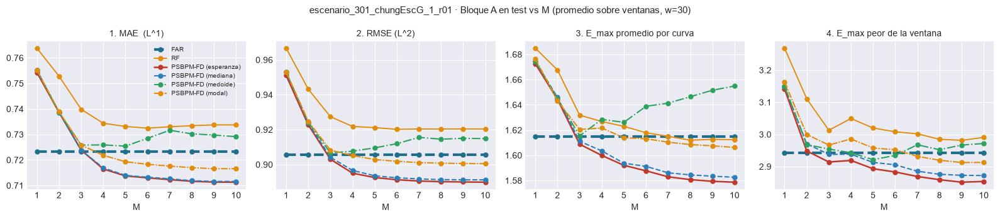

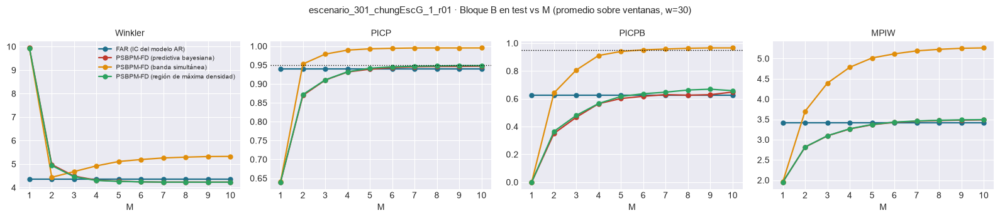

In [15]:
# Las métricas contra M: promedio en test sobre las ventanas, una línea por modelo / banda.
plot_metricas_vs_M(promedio_vs_M(resumen_A, "modelo"), METRICAS_A, ESTILOS_MODELOS_PREDICTORES,
                   f"{EXPERIMENT_BASE} · Bloque A en test vs M (promedio sobre ventanas, w={W_REF})",
                   save_path=PATH_BARRIDO / f"{PREFIJO + 6}_bloqueA_vs_M.png")
plt.show()
plot_metricas_vs_M(promedio_vs_M(resumen_B, "banda"),
                   [("Winkler", "winkler"), ("PICP", "picp"), ("PICPB", "picp_simultaneo"), ("MPIW", "mpiw")],
                   ESTILOS_BANDAS,
                   f"{EXPERIMENT_BASE} · Bloque B en test vs M (promedio sobre ventanas, w={W_REF})",
                   nominal=NIVEL, save_path=PATH_BARRIDO / f"{PREFIJO + 7}_bloqueB_vs_M.png")
plt.show()

### 8.1 Cada construcción del PSBPM-FD contra el FAR

Winkler medio en test menos el del FAR y % de ventanas ganadas cara a cara (`111_*`).

In [16]:
# Cada construcción del PSBPM-FD contra el FAR, cara a cara (111_bloqueB_intervalos_vs_FAR.csv).
VS_FAR = bloqueB_contra_far(EST, PATH_BARRIDO)
for v, fmt, cap in (("dif_winkler_vs_FAR", "{:+.4f}", "Winkler medio TEST de la banda menos el del FAR (negativo: gana la banda)"),
                    ("pct_ventanas_gana_FAR", "{:.1%}", "% de ventanas TEST en que la banda tiene menor Winkler que el FAR")):
    display(VS_FAR.pivot(index="banda", columns="M", values=v).style.format(fmt)
            .background_gradient(cmap="RdYlGn_r" if v.startswith("dif") else "RdYlGn", axis=None)
            .set_caption(f"{cap} (w={W_REF}, sin cruzar T0)"))

M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
PSBPM-FD (banda simultánea),+5.5688,+0.0865,+0.3296,+0.5718,+0.7586,+0.8419,+0.9094,+0.9432,+0.9688,+0.9748
PSBPM-FD (predictiva bayesiana),+5.5927,+0.6258,+0.1365,-0.0361,-0.0822,-0.1086,-0.1198,-0.1194,-0.1208,-0.1188
PSBPM-FD (región de máxima densidad),+5.5819,+0.5847,+0.1110,-0.0486,-0.0888,-0.1097,-0.1201,-0.1203,-0.1219,-0.1203


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
PSBPM-FD (banda simultánea),0.0%,44.3%,17.7%,14.4%,7.7%,6.6%,5.5%,5.5%,5.2%,5.2%
PSBPM-FD (predictiva bayesiana),0.0%,9.6%,26.6%,62.7%,76.0%,80.4%,83.8%,83.4%,82.3%,80.8%
PSBPM-FD (región de máxima densidad),0.0%,8.1%,30.3%,73.1%,81.9%,87.1%,88.6%,89.3%,89.7%,87.8%


## 9. Intervalos de credibilidad: FAR contra PSBPM-FD, en la ventana de detalle

Tres figuras por $M$ (FAR contra equi-colas, HDR y simultánea) y la tabla de ancho y cobertura por origen, con la cobertura de curva completa como cuenta.

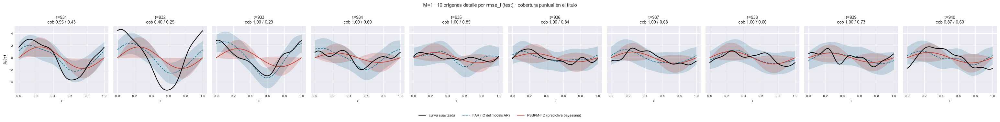

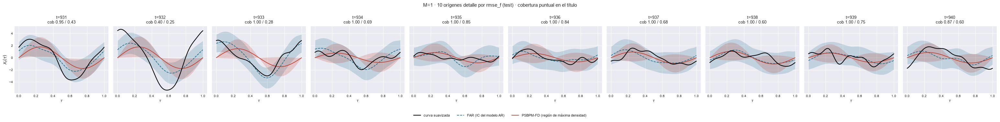

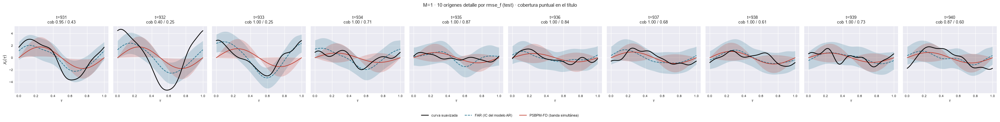

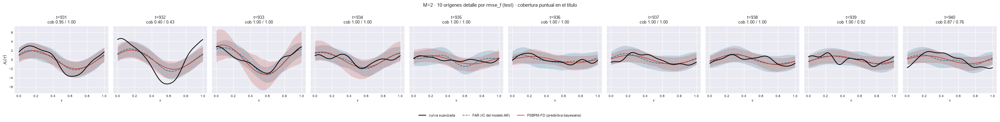

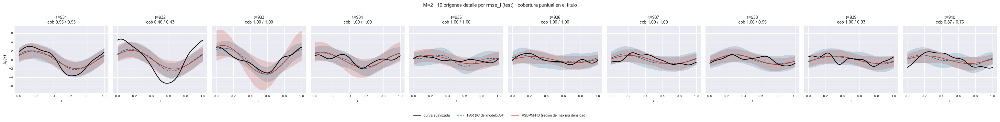

...

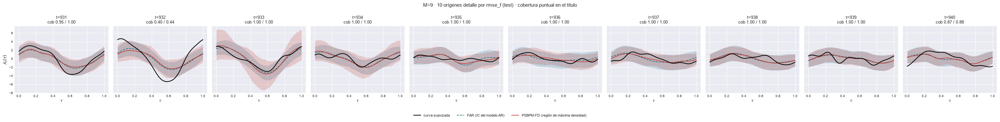

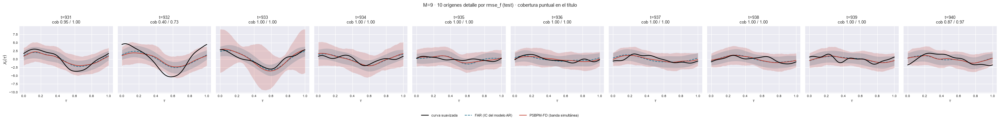

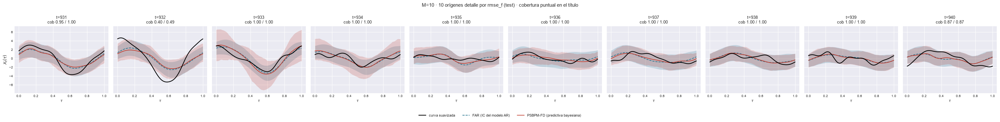

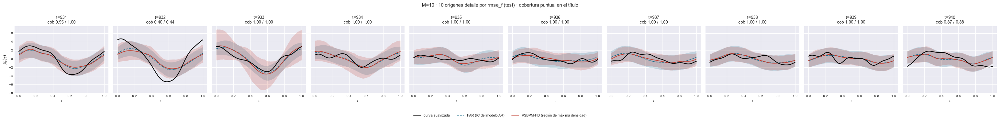

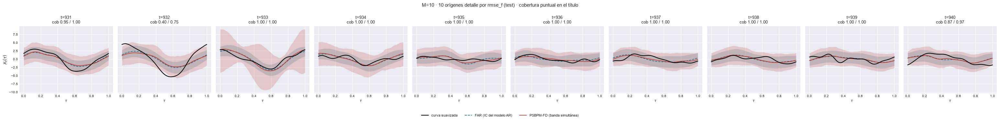

In [17]:
M_9 = M_OK if M_DETALLE is None else tuple(m for m in M_DETALLE if m in M_OK)
DETALLE = {"detalle": IDX_DET}
for M in M_9:
    for par, sufijo in ((BANDA_A_CONTRASTAR, ""), (("FAR", G_PSH), "_hdr"), (("FAR", G_PSS), "_simultanea")):
        plot_bandas_contraste(
            EST[M]["BANDAS"], DETALLE, X_obj_ev, grilla, t_orig, M, METRICA_SEL_IC, par, "detalle",
            EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_detalle{sufijo}.png")
        plt.show()

In [18]:
# Ancho y cobertura por origen de cada banda en la ventana de detalle (79_ic_contraste_origenes.csv por M).
filas = []
for M in M_9:
    for i in IDX_DET:
        for nombre, ((L, U), _Xp) in EST[M]["BANDAS"].items():
            dentro = cobertura_tramos(X_obj_ev[i], L[i], U[i])
            filas.append({"M": M, "t": int(t_orig[i]), "banda": nombre,
                          "mpiw": float(ancho_tramos(L[i], U[i]).mean()),
                          "picp_puntual": float(dentro.mean()), "I_t_simultaneo": float(dentro.all())})
ic_df = pd.DataFrame(filas)
for M in M_9:
    ic_df[ic_df.M == M].drop(columns="M").to_csv(
        EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_origenes.csv", index=False)
display(ic_df.groupby(["M", "banda"]).agg(mpiw=("mpiw", "mean"), picp_puntual=("picp_puntual", "mean"),
                                          curvas_cubiertas=("I_t_simultaneo", "sum"))
        .style.format({"mpiw": "{:.3f}", "picp_puntual": "{:.3f}", "curvas_cubiertas": "{:.0f}"})
        .set_caption(f"Ventana de detalle (t={T0_DET}..): curvas_cubiertas = cuántas de las {N_DETALLE} "
                     "quedan enteras dentro de la banda (descriptivo)"))
print("Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO")
print("depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes")
print("es la flexibilidad de una predictiva que depende del estado.")

Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO
depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes
es la flexibilidad de una predictiva que depende del estado.


## 10. Comportamientos predictivos contra lo observado

En la ventana de detalle, como cuentas: comportamiento en que cae lo observado, su probabilidad, si es el más probable, y cobertura, ancho y Winkler de la banda del comportamiento realizado, del más probable y de la marginal, contra $X_t^{(M)}$. Se espera $K = 1$ salvo en $t = 933$.

In [19]:
# validar_observado sobre TODO el bloque de prueba (las cifras del cuerpo) y, aparte, sobre la ventana de
# detalle (las cuentas de k de 10). La máscara de los comportamientos se restringe a cada subconjunto. Por
# subconjunto y objetivo, dos filas de resumen: todos los orígenes y sólo K >= 2 (donde el comportamiento
# realizado y el más probable se apartan de la marginal). Error en el origen de la curva típica (realizado =
# cota, más probable = pronóstico) y de las referencias puntuales: esperanza del PSBPM-FD, FAR y RF.
SUBCONJUNTOS = {"test": ~es_train, "detalle": MASK_DET}
partes, res = [], []
for M in M_OK:
    e = EST[M]
    C = cargar_comportamientos(e["paths"])
    assert C is not None and np.array_equal(C["t_orig"], t_orig), f"[M={M}] falta el §12 del _04."
    li_f, ls_f = e["BANDA_PSBP"]
    por_M = []
    for sub, mask in SUBCONJUNTOS.items():
        C["mascara"] = mask.copy()
        for objetivo, Y in (("curva_suavizada", X_obj_ev), ("representacion_fpca", e["X_proj"])):
            v = validar_observado(C, e["Y_obs"], Y, li_f, ls_f, grilla, PESOS_TAU,
                                  curvas_ref={"esperanza": e["X_PSBP"], "FAR": e["CURVAS"]["FAR"],
                                              "RF": e["CURVAS"]["RF"]})
            v.insert(0, "subconjunto", sub)
            v.insert(1, "objetivo", objetivo)
            v.insert(2, "t", t_orig[v["i"].to_numpy()])
            por_M.append(v)
            for grupo, g in (("todos", v), ("K>=2", v[v.K >= 2])):
                fila = {"M": M, "subconjunto": sub, "objetivo": objetivo, "origenes": grupo, "n": int(len(g))}
                if len(g):
                    fila.update({"K >= 2": int((g.K >= 2).sum()),
                                 "cae en el más probable": float(g.acierto.mean()),
                                 "p_obs media": float(g.p_obs.mean()), "p_esperada media": float(g.p_esperada.mean()),
                                 **{f"{m}_{k}": float(g[f"{m}_{k}"].mean()) for m in ("mae", "rmse")
                                    for k in ("real", "mp", "esperanza", "FAR", "RF")},
                                 "mp gana a FAR": float((g.mae_mp < g.mae_FAR).mean()),
                                 "mp gana a RF": float((g.mae_mp < g.mae_RF).mean()),
                                 "mp gana a esperanza": float((g.mae_mp < g.mae_esperanza).mean()),
                                 "curva entera en banda real": float(g.picpb_real.mean()),
                                 "curva entera en banda mp": float(g.picpb_mp.mean()),
                                 "curva entera en banda marginal": float(g.picpb_marg.mean()),
                                 "mpiw_real": float(g.mpiw_real.mean()), "mpiw_mp": float(g.mpiw_mp.mean()),
                                 "mpiw_marg": float(g.mpiw_marg.mean()), "winkler_real": float(g.winkler_real.mean()),
                                 "winkler_mp": float(g.winkler_mp.mean()), "winkler_marg": float(g.winkler_marg.mean())})
                res.append(fila)
    pd.concat(por_M, ignore_index=True).to_csv(e["paths"]["out_report"] / "82_validacion_comportamientos.csv",
                                              index=False)
    pd.DataFrame([r for r in res if r["M"] == M]).to_csv(e["paths"]["out_report"] / "83_validacion_resumen.csv",
                                                         index=False)
VAL_COMP = pd.DataFrame(res).assign(t0_detalle=T0_DET)
VAL_COMP.to_csv(PATH_BARRIDO / "105_validacion_comportamientos_por_M.csv", index=False)
COLS = ["n", "K >= 2", "cae en el más probable", "mae_mp", "mae_real", "mae_esperanza", "mae_FAR", "mae_RF",
        "mp gana a FAR", "mp gana a RF", "mp gana a esperanza", "curva entera en banda marginal"]
for sub, nota in (("test", "fracciones sobre todo el bloque de prueba"),
                  ("detalle", f"ventana de detalle t={T0_DET}..{T0_DET + N_DETALLE - 1}: fracciones de {N_DETALLE} orígenes")):
    display(VAL_COMP[(VAL_COMP.subconjunto == sub) & (VAL_COMP.objetivo == "curva_suavizada")]
            .set_index(["M", "origenes"])[COLS].style.format(precision=3)
            .set_caption(f"Comportamientos contra lo observado · {nota} · objetivo = curva suavizada"))


,origenes,K >= 2,cae en el más probable,p_obs media,p_esperada media,mae_real,mae_mp,mae_esperanza,mae_FAR,mae_RF,rmse_real,rmse_mp,rmse_esperanza,rmse_FAR,rmse_RF,mp gana a FAR,mp gana a RF,mp gana a esperanza,curva entera en banda real,curva entera en banda mp,curva entera en banda marginal,mpiw_real,mpiw_mp,mpiw_marg,winkler_real,winkler_mp,winkler_marg
M,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,10,0,10,1.000,1.000,0.253,0.253,0.254,0.669,0.260,0.281,0.281,0.283,0.755,0.289,10,5,5,10,10,10,1.933,1.933,1.955,1.959,1.959,1.981
2,10,1,10,0.960,0.952,0.702,0.702,0.689,0.709,0.778,0.780,0.780,0.766,0.813,0.864,6,6,5,8,8,8,3.142,3.142,3.287,5.151,5.151,5.224
3,10,1,10,0.960,0.952,0.734,0.734,0.721,0.741,0.812,0.835,0.835,0.822,0.854,0.921,6,7,5,8,8,8,3.399,3.399,3.530,5.141,5.141,5.255
4,10,1,10,0.960,0.952,0.755,0.755,0.742,0.759,0.832,0.868,0.868,0.854,0.875,0.952,6,7,5,8,8,8,3.540,3.540,3.670,5.239,5.239,5.328
5,10,1,10,0.960,0.952,0.771,0.771,0.756,0.764,0.848,0.881,0.881,0.868,0.886,0.969,6,7,5,8,8,8,3.643,3.643,3.778,5.242,5.242,5.334
6,10,1,10,0.960,0.952,0.792,0.792,0.774,0.776,0.863,0.900,0.900,0.888,0.905,0.988,5,7,5,8,8,7,3.696,3.696,3.833,5.274,5.274,5.340
7,10,1,10,0.960,0.952,0.794,0.794,0.777,0.780,0.868,0.904,0.904,0.892,0.910,0.991,5,7,5,8,8,8,3.721,3.721,3.860,5.291,5.291,5.342
8,10,1,10,0.960,0.952,0.796,0.796,0.779,0.785,0.874,0.909,0.909,0.897,0.916,0.996,5,7,5,8,8,8,3.738,3.738,3.877,5.345,5.345,5.395
9,10,1,10,0.960,0.952,0.797,0.797,0.779,0.785,0.871,0.914,0.914,0.901,0.921,1.000,5,7,5,8,8,8,3.748,3.748,3.885,5.332,5.332,5.349


,origenes,K >= 2,cae en el más probable,p_obs media,p_esperada media,mae_real,mae_mp,mae_esperanza,mae_FAR,mae_RF,rmse_real,rmse_mp,rmse_esperanza,rmse_FAR,rmse_RF,mp gana a FAR,mp gana a RF,mp gana a esperanza,curva entera en banda real,curva entera en banda mp,curva entera en banda marginal,mpiw_real,mpiw_mp,mpiw_marg,winkler_real,winkler_mp,winkler_marg
M,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,10,0,10,1.000,1.000,0.982,0.982,0.983,0.787,0.993,1.120,1.120,1.121,0.923,1.133,4,5,6,0,0,0,1.933,1.933,1.955,19.535,19.535,19.358
2,10,1,10,0.960,0.952,0.806,0.806,0.785,0.787,0.867,0.923,0.923,0.911,0.923,0.997,4,6,5,4,4,7,3.142,3.142,3.287,5.713,5.713,5.742
3,10,1,10,0.960,0.952,0.800,0.800,0.783,0.787,0.866,0.917,0.917,0.905,0.923,0.997,5,7,5,7,7,8,3.399,3.399,3.530,5.329,5.329,5.436
4,10,1,10,0.960,0.952,0.806,0.806,0.789,0.787,0.872,0.924,0.924,0.912,0.923,1.004,5,7,5,7,7,7,3.540,3.540,3.670,5.348,5.348,5.435
5,10,1,10,0.960,0.952,0.798,0.798,0.782,0.787,0.869,0.916,0.916,0.904,0.923,1.001,5,7,5,8,8,8,3.643,3.643,3.778,5.343,5.343,5.440
6,10,1,10,0.960,0.952,0.800,0.800,0.784,0.787,0.874,0.917,0.917,0.904,0.923,1.003,5,7,5,8,8,8,3.696,3.696,3.833,5.308,5.308,5.377
7,10,1,10,0.960,0.952,0.799,0.799,0.783,0.787,0.872,0.917,0.917,0.904,0.923,1.002,5,7,5,7,7,8,3.721,3.721,3.860,5.323,5.323,5.384
8,10,1,10,0.960,0.952,0.797,0.797,0.781,0.787,0.871,0.916,0.916,0.904,0.923,1.003,5,7,5,8,8,8,3.738,3.738,3.877,5.338,5.338,5.398
9,10,1,10,0.960,0.952,0.796,0.796,0.780,0.787,0.871,0.915,0.915,0.903,0.923,1.001,5,7,5,8,8,8,3.748,3.748,3.885,5.326,5.326,5.344
